In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score
from sklearn import linear_model, metrics
import warnings


In [65]:
import torch
import random
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
)
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Dataset

SEED = 520
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)

PyTorch: 2.11.0+cu128
Device: cuda


In [4]:
df  = pd.read_csv(r"C:\WVU-Courses\CPE520\Code_Group2-1\Code_Group2\Fermentation_NN\100_Batches_IndPenSim_V3.csv")
df.columns

Index(['Time (h)', 'Aeration rate(Fg:L/h)', 'Agitator RPM(RPM:RPM)',
       'Sugar feed rate(Fs:L/h)', 'Acid flow rate(Fa:L/h)',
       'Base flow rate(Fb:L/h)', 'Heating/cooling water flow rate(Fc:L/h)',
       'Heating water flow rate(Fh:L/h)',
       'Water for injection/dilution(Fw:L/h)',
       'Air head pressure(pressure:bar)',
       ...
       '210', '209', '208', '207', '206', '205', '204', '203', '202', '201'],
      dtype='str', length=2239)

In [5]:
print(f'The dataset has {len(df)} rows and {len(df.columns)} columns.')

The dataset has 113935 rows and 2239 columns.


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 113935 entries, 0 to 113934
Columns: 2239 entries, Time (h) to 201
dtypes: float64(2225), int64(14)
memory usage: 1.9 GB


In [7]:
df.isnull().sum()

Time (h)                        0
Aeration rate(Fg:L/h)           0
Agitator RPM(RPM:RPM)           0
Sugar feed rate(Fs:L/h)         0
Acid flow rate(Fa:L/h)          0
                            ...  
205                             0
204                             0
203                             0
202                        113935
201                        113935
Length: 2239, dtype: int64

Index([], dtype='str')

In [9]:
raman_cols = df.columns[39:]
df.drop(raman_cols, axis=1, inplace=True)

In [10]:
for i in df.columns:
    print(i, ":", df[i].nunique())
    print('='*50)

Time (h) : 1450
Aeration rate(Fg:L/h) : 7
Agitator RPM(RPM:RPM) : 1
Sugar feed rate(Fs:L/h) : 25
Acid flow rate(Fa:L/h) : 1353
Base flow rate(Fb:L/h) : 67206
Heating/cooling water flow rate(Fc:L/h) : 77380
Heating water flow rate(Fh:L/h) : 54534
Water for injection/dilution(Fw:L/h) : 6
Air head pressure(pressure:bar) : 6
Dumped broth flow(Fremoved:L/h) : 2
Substrate concentration(S:g/L) : 64531
Dissolved oxygen concentration(DO2:mg/L) : 11087
Penicillin concentration(P:g/L) : 56258
Vessel Volume(V:L) : 28296
Vessel Weight(Wt:Kg) : 31711
pH(pH:pH) : 3990
Temperature(T:K) : 393
Generated heat(Q:kJ) : 51059
carbon dioxide percent in off-gas(CO2outgas:%) : 28416
PAA flow(Fpaa:PAA flow (L/h)) : 22931
PAA concentration offline(PAA_offline:PAA (g L^{-1})) : 1563
Oil flow(Foil:L/hr) : 9
NH_3 concentration off-line(NH3_offline:NH3 (g L^{-1})) : 1759
Oxygen Uptake Rate(OUR:(g min^{-1})) : 35065
Oxygen in percent in off-gas(O2:O2  (%)) : 3095
Offline Penicillin concentration(P_offline:P(g L^{-1})

In [11]:
df.isna().sum()[df.isna().sum()>0]

PAA concentration offline(PAA_offline:PAA (g L^{-1}))      111873
NH_3 concentration off-line(NH3_offline:NH3 (g L^{-1}))    111873
Offline Penicillin concentration(P_offline:P(g L^{-1}))    111873
Offline Biomass concentratio(X_offline:X(g L^{-1}))        111873
Viscosity(Viscosity_offline:centPoise)                     111873
dtype: int64

In [291]:
print(df.columns.tolist())

['Time (h)', 'Aeration rate(Fg:L/h)', 'Sugar feed rate(Fs:L/h)', 'Acid flow rate(Fa:L/h)', 'Base flow rate(Fb:L/h)', 'Heating/cooling water flow rate(Fc:L/h)', 'Heating water flow rate(Fh:L/h)', 'Water for injection/dilution(Fw:L/h)', 'Air head pressure(pressure:bar)', 'Dumped broth flow(Fremoved:L/h)', 'Substrate concentration(S:g/L)', 'Dissolved oxygen concentration(DO2:mg/L)', 'Penicillin concentration(P:g/L)', 'Vessel Volume(V:L)', 'Vessel Weight(Wt:Kg)', 'pH(pH:pH)', 'Temperature(T:K)', 'Generated heat(Q:kJ)', 'carbon dioxide percent in off-gas(CO2outgas:%)', 'PAA flow(Fpaa:PAA flow (L/h))', 'Oil flow(Foil:L/hr)', 'Oxygen Uptake Rate(OUR:(g min^{-1}))', 'Oxygen in percent in off-gas(O2:O2  (%))', 'Carbon evolution rate(CER:g/h)', 'Fault reference(Fault_ref:Fault ref)', 'Batch reference(Batch_ref:Batch ref)', 'Batch number']


In [12]:
df.isna().sum()[df.isna().sum()>0]
df =df.drop(columns=['2-PAT control(PAT_ref:PAT ref)','1-Raman spec recorded ' ,'2-PAT control(PAT_ref:PAT ref) ','0 - Recipe driven 1 - Operator controlled(Control_ref:Control ref)','Fault flag','1-Raman spec recorded','Fault code','PAA concentration offline(PAA_offline:PAA (g L^{-1}))','NH_3 concentration off-line(NH3_offline:NH3 (g L^{-1}))','Offline Penicillin concentration(P_offline:P(g L^{-1}))','Offline Biomass concentratio(X_offline:X(g L^{-1}))','1- No Raman spec'], errors='ignore')
df =df.drop(columns = ['Viscosity(Viscosity_offline:centPoise)','Ammonia shots(NH3_shots:kgs)','Agitator RPM(RPM:RPM)',' 1-Raman spec recorded',
                        'Batch ID'], errors='ignore') 

In [13]:
is_start = np.isclose(df['Time (h)'], 0.2)
batch_start = df.index[is_start]
batch_end_indices = np.append(batch_start[1:] - 1, len(df) - 1)

df['Batch number'] = is_start.cumsum()

print('Batches found:', df['Batch number'].nunique())                 # should be 100
print('Rows per batch: min', df['Batch number'].value_counts().min(),
      '| max', df['Batch number'].value_counts().max())
batch_end_indices

Batches found: 100
Rows per batch: min 835 | max 1450


array([  1129,   2279,   3669,   4819,   5714,   6864,   8024,   9174,
        10434,  11584,  12594,  13744,  14824,  15974,  16879,  18029,
        18969,  20119,  21154,  22304,  23444,  24594,  25914,  27064,
        28369,  29519,  30574,  31724,  33174,  34324,  35574,  36724,
        38024,  39174,  40154,  41304,  42354,  43504,  44679,  45829,
        47044,  48194,  49349,  50499,  51809,  52959,  54099,  55249,
        56409,  57559,  58684,  59834,  60799,  61949,  63069,  64219,
        65389,  66539,  67559,  68709,  69914,  71064,  72214,  73364,
        74519,  75669,  76504,  77654,  78779,  79929,  80999,  82149,
        83329,  84479,  85439,  86589,  87614,  88764,  89939,  91089,
        92189,  93339,  94544,  95694,  96694,  97844,  98954, 100104,
       101259, 102409, 103699, 104849, 105899, 107049, 108104, 109254,
       110379, 111529, 112784, 113934])

In [14]:
batch_df = df.iloc[batch_end_indices]
batch_df 

,Time (h),Aeration rate(Fg:L/h),Sugar feed rate(Fs:L/h),Acid flow rate(Fa:L/h),Base flow rate(Fb:L/h),Heating/cooling water flow rate(Fc:L/h),Heating water flow rate(Fh:L/h),Water for injection/dilution(Fw:L/h),Air head pressure(pressure:bar),Dumped broth flow(Fremoved:L/h),...,Generated heat(Q:kJ),carbon dioxide percent in off-gas(CO2outgas:%),PAA flow(Fpaa:PAA flow (L/h)),Oil flow(Foil:L/hr),Oxygen Uptake Rate(OUR:(g min^{-1})),Oxygen in percent in off-gas(O2:O2 (%)),Carbon evolution rate(CER:g/h),Fault reference(Fault_ref:Fault ref),Batch reference(Batch_ref:Batch ref),Batch number
1129,226.0,65,80,0.000,200.3000,42.8750,1.2727,250,0.9,0,...,16.912,1.77180,4.0,23,1.27630,0.19061,1.46690,0,0,1
2279,230.0,65,80,0.000,44.1360,1.8578,0.0001,250,0.9,0,...,34.311,1.52220,4.0,23,1.03340,0.19321,1.25930,0,0,2
3669,278.0,60,80,0.000,24.4660,63.6390,444.2800,100,0.9,0,...,833.800,0.96230,4.0,23,0.55138,0.19809,0.73368,0,0,3
4819,230.0,65,80,0.000,15.7810,75.7280,1.6785,250,0.9,0,...,194.570,1.17820,4.0,23,0.26071,0.20055,0.97370,0,0,4
5714,179.0,75,80,0.000,63.6400,111.6700,14.9050,150,0.9,0,...,78.645,1.61990,10.0,23,1.37300,0.19166,1.54670,0,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109254,230.0,65,80,0.000,14.7720,73.4010,10.5370,250,0.9,0,...,157.290,1.35280,4.0,23,0.54856,0.19773,1.11860,0,1,96
110379,225.0,65,80,0.000,6.5491,57.7560,1.1040,250,0.9,0,...,286.150,1.40140,4.0,23,0.69632,0.19636,1.15890,0,1,97
111529,230.0,65,80,0.000,60.4400,70.9450,11.0470,250,0.9,0,...,126.130,1.50820,4.0,23,0.89484,0.19443,1.24770,0,1,98
112784,251.0,60,80,1.037,0.0000,281.7100,6.7026,0,0.9,-4000,...,193.280,0.86992,4.0,23,0.30526,0.20057,0.66308,0,1,99


In [15]:
batch_df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Time (h),100.0,227.870000,1.815069e+01,167.000000,227.500000,230.000000,230.000000,290.00000
Aeration rate(Fg:L/h),100.0,65.350000,3.198406e+00,60.000000,65.000000,65.000000,65.000000,75.00000
Sugar feed rate(Fs:L/h),100.0,81.800000,1.957271e+01,20.000000,80.000000,80.000000,80.000000,150.00000
Acid flow rate(Fa:L/h),100.0,0.155721,6.618278e-01,0.000000,0.000000,0.000000,0.000000,4.15080
Base flow rate(Fb:L/h),100.0,37.788269,3.775116e+01,0.000000,9.951425,29.927000,54.146750,200.30000
Heating/cooling water flow rate(Fc:L/h),100.0,47.035829,4.475456e+01,0.000100,14.768500,32.771500,68.589250,281.71000
Heating water flow rate(Fh:L/h),100.0,42.467140,6.897390e+01,0.000100,1.612250,9.296450,67.956750,444.28000
Water for injection/dilution(Fw:L/h),100.0,224.000000,7.159087e+01,0.000000,250.000000,250.000000,250.000000,400.00000
Air head pressure(pressure:bar),100.0,0.900000,4.463264e-16,0.900000,0.900000,0.900000,0.900000,0.90000
Dumped broth flow(Fremoved:L/h),100.0,-400.000000,1.206045e+03,-4000.000000,0.000000,0.000000,0.000000,0.00000


In [16]:
print(f'The dataset has {batch_df.shape[0]} rows and {batch_df.shape[1]} columns')

The dataset has 100 rows and 27 columns


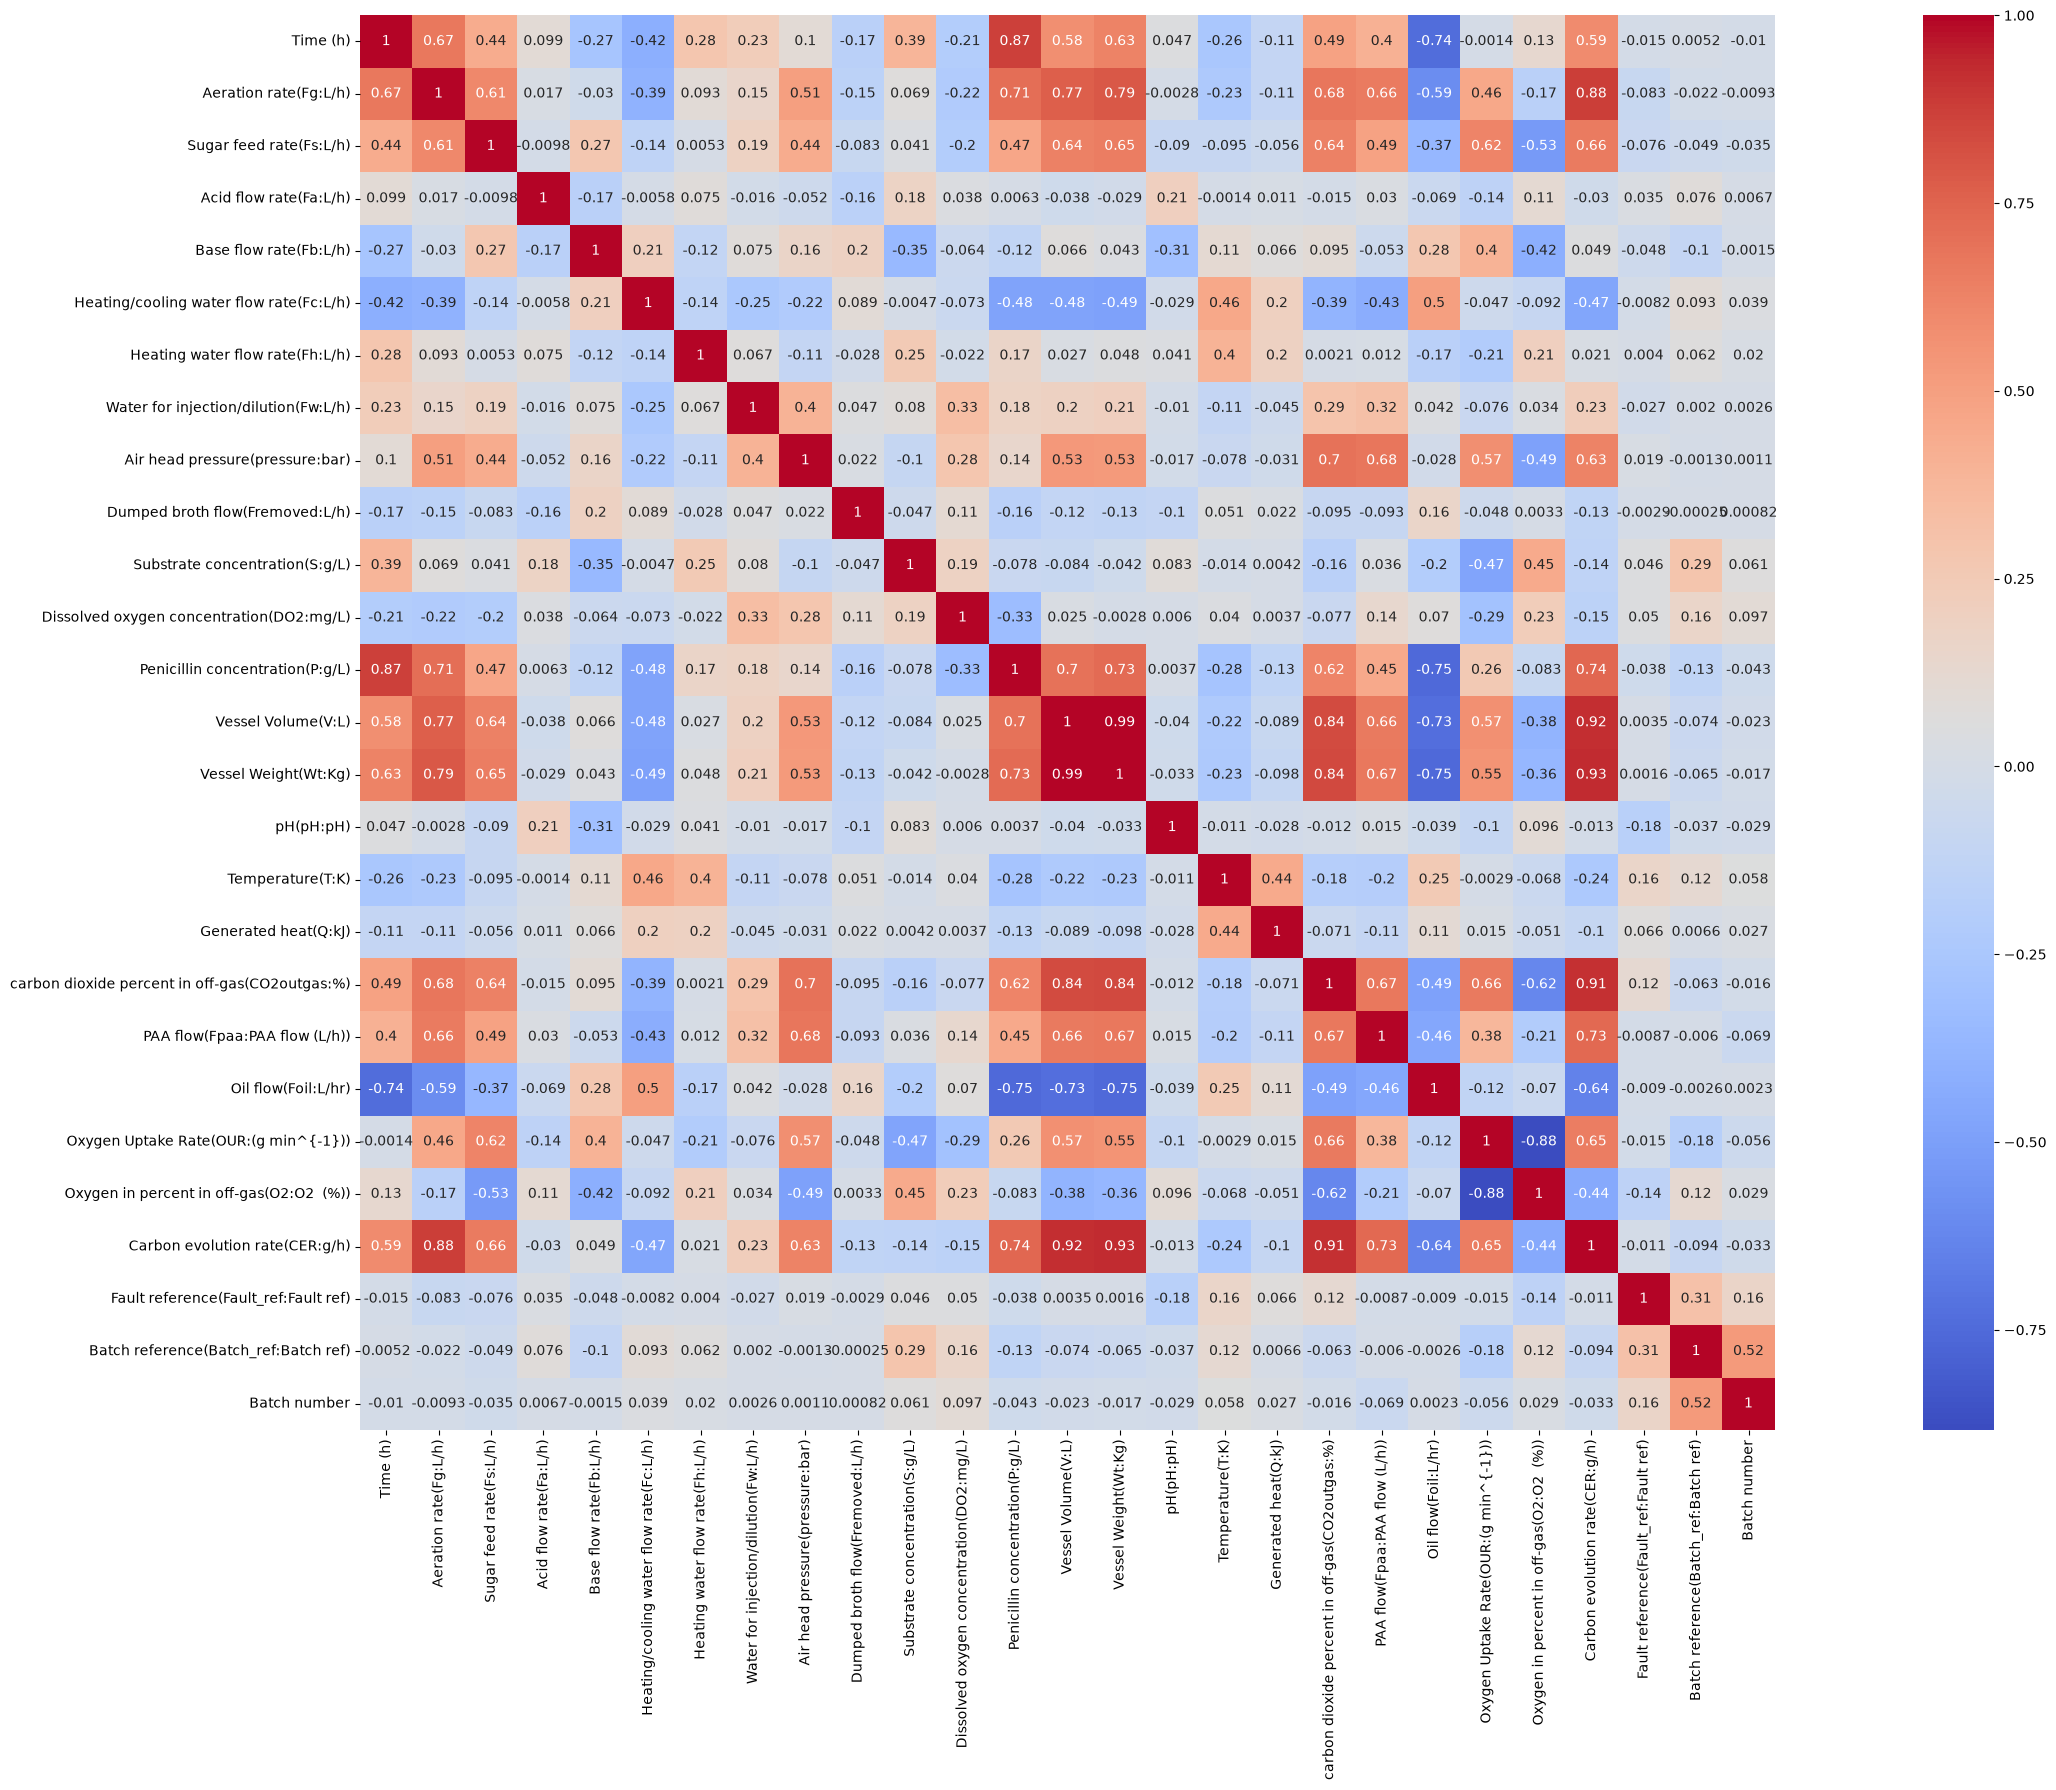

In [17]:
plt.figure(figsize=(30,18))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm",  square=True)
plt.tight_layout()
plt.show()

In [18]:
batch_df.info()

<class 'pandas.DataFrame'>
Index: 100 entries, 1129 to 113934
Data columns (total 27 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Time (h)                                        100 non-null    float64
 1   Aeration rate(Fg:L/h)                           100 non-null    int64  
 2   Sugar feed rate(Fs:L/h)                         100 non-null    int64  
 3   Acid flow rate(Fa:L/h)                          100 non-null    float64
 4   Base flow rate(Fb:L/h)                          100 non-null    float64
 5   Heating/cooling water flow rate(Fc:L/h)         100 non-null    float64
 6   Heating water flow rate(Fh:L/h)                 100 non-null    float64
 7   Water for injection/dilution(Fw:L/h)            100 non-null    int64  
 8   Air head pressure(pressure:bar)                 100 non-null    float64
 9   Dumped broth flow(Fremoved:L/h)                 100 n

In [19]:
batch_df['Batch number'].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100])

In [20]:
faulty_col = 'Fault reference(Fault_ref:Fault ref)'
time_col   = 'Time (h)'
batch_col  = 'Batch number'                              
batchref_col = 'Batch reference(Batch_ref:Batch ref)'   
print('Number of batches:', df[batch_col].nunique())    
feature_cols = [c for c in df.columns if c not in (time_col, faulty_col, batch_col, batchref_col)]  
print('Number of features:', len(feature_cols))         
print(f'The features are: {feature_cols}')

Number of batches: 100
Number of features: 23
The features are: ['Aeration rate(Fg:L/h)', 'Sugar feed rate(Fs:L/h)', 'Acid flow rate(Fa:L/h)', 'Base flow rate(Fb:L/h)', 'Heating/cooling water flow rate(Fc:L/h)', 'Heating water flow rate(Fh:L/h)', 'Water for injection/dilution(Fw:L/h)', 'Air head pressure(pressure:bar)', 'Dumped broth flow(Fremoved:L/h)', 'Substrate concentration(S:g/L)', 'Dissolved oxygen concentration(DO2:mg/L)', 'Penicillin concentration(P:g/L)', 'Vessel Volume(V:L)', 'Vessel Weight(Wt:Kg)', 'pH(pH:pH)', 'Temperature(T:K)', 'Generated heat(Q:kJ)', 'carbon dioxide percent in off-gas(CO2outgas:%)', 'PAA flow(Fpaa:PAA flow (L/h))', 'Oil flow(Foil:L/hr)', 'Oxygen Uptake Rate(OUR:(g min^{-1}))', 'Oxygen in percent in off-gas(O2:O2  (%))', 'Carbon evolution rate(CER:g/h)']


In [21]:
batch_has_fault = df.groupby(batch_col)[faulty_col].max()
faulty_batches  = batch_has_fault[batch_has_fault == 1].index.to_numpy()
healthy_batches = batch_has_fault[batch_has_fault == 0].index.to_numpy()
print(f'There are {len(faulty_batches)} faulty batches and {len(healthy_batches)} fault-free batches')  

There are 10 faulty batches and 90 fault-free batches


In [404]:
def splitdata(batches, val_ratio, test_ratio, rng):
    b = rng.permutation(batches)
    n_test = max(1, round(len(b) * test_ratio))
    n_val  = max(1, round(len(b) * val_ratio))
    return b[n_test + n_val:], b[n_test:n_test + n_val], b[:n_test]

rng = np.random.default_rng(SEED)
normal_train, normal_val, normal_test = splitdata(healthy_batches, 0.25, 0.25, rng)
faulty_train, faulty_val, faulty_test = splitdata(faulty_batches,  0.3, 0.2, rng)

train_batches = np.concatenate([normal_train, faulty_train])
val_batches   = np.concatenate([normal_val, faulty_val])
test_batches  = np.concatenate([normal_test, faulty_test])

print('Train batches:', sorted(train_batches.tolist()))
print('Validation batches  :', sorted(val_batches.tolist()))
print('Test batches :', sorted(test_batches.tolist()))

train_df = df[df[batch_col].isin(train_batches)]
val_df   = df[df[batch_col].isin(val_batches)]
test_df  = df[df[batch_col].isin(test_batches)]
for name, b in [('train', faulty_train), ('val', faulty_val), ('test', faulty_test)]:
    assert len(b) > 0, f'No faulty batch in the {name} set'

Train batches: [1, 6, 8, 9, 14, 16, 17, 18, 19, 21, 22, 24, 26, 28, 31, 32, 33, 36, 37, 39, 41, 43, 44, 47, 48, 50, 51, 53, 54, 56, 57, 59, 60, 61, 64, 65, 72, 73, 75, 77, 78, 79, 81, 85, 86, 89, 92, 93, 94, 97, 99]
Validation batches  : [5, 7, 11, 29, 35, 38, 40, 42, 45, 52, 55, 58, 62, 63, 68, 71, 74, 80, 84, 87, 88, 90, 91, 96, 100]
Test batches : [2, 3, 4, 10, 12, 13, 15, 20, 23, 25, 27, 30, 34, 46, 49, 66, 67, 69, 70, 76, 82, 83, 95, 98]


In [405]:
test_df.nunique()

Time (h)                                           1390
Aeration rate(Fg:L/h)                                 6
Sugar feed rate(Fs:L/h)                              22
Acid flow rate(Fa:L/h)                              490
Base flow rate(Fb:L/h)                            22502
Heating/cooling water flow rate(Fc:L/h)           23871
Heating water flow rate(Fh:L/h)                   15165
Water for injection/dilution(Fw:L/h)                  6
Air head pressure(pressure:bar)                       6
Dumped broth flow(Fremoved:L/h)                       2
Substrate concentration(S:g/L)                    22002
Dissolved oxygen concentration(DO2:mg/L)           6663
Penicillin concentration(P:g/L)                   21528
Vessel Volume(V:L)                                16596
Vessel Weight(Wt:Kg)                              17434
pH(pH:pH)                                          2310
Temperature(T:K)                                    197
Generated heat(Q:kJ)                            

In [406]:
print('Unique batches:', df[batch_col].nunique())
print('Faulty batches:', faulty_batches.tolist())

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f'{name:5s}: {len(d):6d} rows | {d[batch_col].nunique():3d} batches | fault rows = {int(d[faulty_col].sum())}')
print('Rows in df:', len(df), '| rows across splits:', len(train_df) + len(val_df) + len(test_df))

Unique batches: 100
Faulty batches: [91, 92, 93, 94, 95, 96, 97, 98, 99, 100]
train:  57905 rows |  51 batches | fault rows = 570
val  :  28645 rows |  25 batches | fault rows = 376
test :  27385 rows |  24 batches | fault rows = 310
Rows in df: 113935 | rows across splits: 113935


In [407]:
scaler = StandardScaler().fit(train_df[feature_cols])

def scale(x):
    x = x.copy()         
    x[feature_cols] = scaler.transform(x[feature_cols])
    return x

train_df, val_df, test_df = scale(train_df), scale(val_df), scale(test_df)
batch_size = 512

loss_fn = nn.BCEWithLogitsLoss()

In [408]:
def to_tensors(d):
    X = torch.tensor(d[feature_cols].to_numpy(), dtype=torch.float32)
    y = torch.tensor(d[faulty_col].to_numpy(), dtype=torch.float32)
    return X, y

X_train_mlp, y_train_mlp = to_tensors(train_df)
X_val_mlp,   y_val_mlp   = to_tensors(val_df)
X_test_mlp,  y_test_mlp  = to_tensors(test_df)

g_mlp = torch.Generator().manual_seed(SEED)
mlp_train_loader = DataLoader(TensorDataset(X_train_mlp, y_train_mlp),
                              batch_size=batch_size, shuffle=True, generator=g_mlp)
mlp_val_loader   = DataLoader(TensorDataset(X_val_mlp, y_val_mlp),
                              batch_size=batch_size, shuffle=False)
mlp_test_loader  = DataLoader(TensorDataset(X_test_mlp, y_test_mlp),
                              batch_size=batch_size, shuffle=False)

print('MLP train:')

print('MLP shapes:', X_train_mlp.shape, X_val_mlp.shape, X_test_mlp.shape)

MLP train:
MLP shapes: torch.Size([57905, 23]) torch.Size([28645, 23]) torch.Size([27385, 23])


In [409]:
from sklearn.metrics import precision_recall_curve, average_precision_score, classification_report, ConfusionMatrixDisplay
import copy

class MLP(nn.Module):
    def __init__(self, n_in, hidden=(134,123,155,94,18), dropout=0.110):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))     
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)        

mlp = MLP(n_in=len(feature_cols)).to(DEVICE)
print(mlp)
print('Trainable parameters:', sum(p.numel() for p in mlp.parameters() if p.requires_grad))

MLP(
  (net): Sequential(
    (0): Linear(in_features=23, out_features=134, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.11, inplace=False)
    (3): Linear(in_features=134, out_features=123, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.11, inplace=False)
    (6): Linear(in_features=123, out_features=155, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.11, inplace=False)
    (9): Linear(in_features=155, out_features=94, bias=True)
    (10): ReLU()
    (11): Dropout(p=0.11, inplace=False)
    (12): Linear(in_features=94, out_features=18, bias=True)
    (13): ReLU()
    (14): Dropout(p=0.11, inplace=False)
    (15): Linear(in_features=18, out_features=1, bias=True)
  )
)
Trainable parameters: 55434


In [ ]:
def fit(model, train_loader, val_loader, criterion, epochs=100, lr=0.0017, patience=5):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'val_ap': [], 'val_precision': [],
               'val_accuracy': [], 'val_recall': [], 'val_f1': []}

    best_recall, best_ap, best_state, wait, best_epoch = float('-inf'), float('-inf'), None, 0, 0

    for epoch in range(1, epochs + 1):
    
        model.train()
        running = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(train_loader.dataset)

      
        model.eval()
        running, probs, targets = 0.0, [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                running += criterion(logits, yb).item() * len(xb)
                probs.append(torch.sigmoid(logits).cpu())
                targets.append(yb.cpu())
        val_loss = running / len(val_loader.dataset)

        
       
        y_true = torch.cat(targets).numpy()
        y_prob = torch.cat(probs).numpy()
        y_pred = (y_prob > 0.5).astype(int)

        val_ap        = average_precision_score(y_true, y_prob)
        val_precision = precision_score(y_true, y_pred, zero_division=0)
        val_accuracy  = accuracy_score(y_true, y_pred)
        val_recall    = recall_score(y_true, y_pred, zero_division=0)
        val_f1        = f1_score(y_true, y_pred, zero_division=0)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_ap'].append(val_ap)
        history['val_precision'].append(val_precision)
        history['val_accuracy'].append(val_accuracy)
        history['val_recall'].append(val_recall)
        history['val_f1'].append(val_f1)

        if epoch == 1 or epoch % 5 == 0:
            print(f'epoch {epoch:3d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | '
                  f'AP {val_ap:.4f} | val precision {val_precision:.4f} | val accuracy {val_accuracy:.4f} | '
                  f'val recall {val_recall:.4f} | val f1 {val_f1:.4f}')

    
        improved = (val_recall > best_recall) or (val_recall == best_recall and val_ap > best_ap)
        if improved:
            best_recall, best_ap, wait = val_recall, val_ap, 0
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
        else:
            wait += 1
            if wait >= patience:
                print(f'Early stopping at epoch {epoch}.')
                break

    model.load_state_dict(best_state)
    print(f'Restored best model from epoch {best_epoch} '
          f'(val recall {best_recall:.3f}, val AP {best_ap:.3f}), f1 score {val_f1:.3f}')
    history['best_epoch'] = best_epoch
    return history

In [411]:
torch.manual_seed(SEED)
mlp = MLP(n_in=len(feature_cols)).to(DEVICE)
mlp_history = fit(mlp, mlp_train_loader, mlp_val_loader, loss_fn, epochs=100, lr=0.0017, patience=5)

epoch   1 | train loss 0.0750 | val loss 0.0448 | AP 0.6502 | val precision 1.0000 | val accuracy 0.9869 | val recall 0.0027 | val f1 0.0053
epoch   5 | train loss 0.0013 | val loss 0.0424 | AP 0.7787 | val precision 0.9962 | val accuracy 0.9961 | val recall 0.7048 | val f1 0.8255
epoch  10 | train loss 0.0011 | val loss 0.0370 | AP 0.8119 | val precision 0.9716 | val accuracy 0.9962 | val recall 0.7287 | val f1 0.8328
epoch  15 | train loss 0.0005 | val loss 0.0722 | AP 0.7534 | val precision 0.9892 | val accuracy 0.9964 | val recall 0.7314 | val f1 0.8410
epoch  20 | train loss 0.0012 | val loss 0.0385 | AP 0.7833 | val precision 0.9893 | val accuracy 0.9964 | val recall 0.7367 | val f1 0.8445
epoch  25 | train loss 0.0002 | val loss 0.0705 | AP 0.7755 | val precision 1.0000 | val accuracy 0.9965 | val recall 0.7314 | val f1 0.8449
Early stopping at epoch 25.
Restored best model from epoch 20 (val recall 0.737, val AP 0.783), f1 score 0.845


In [412]:
@torch.no_grad()
def run_epoch(model, loader, criterion):
    """Evaluate a classifier -> (mean loss, P(fault), true labels) as numpy arrays."""
    model.eval()
    running, probs, targets = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        running += criterion(logits, yb).item() * len(xb)
        probs.append(torch.sigmoid(logits).cpu())
        targets.append(yb.cpu())
    return running / len(loader.dataset), torch.cat(probs).numpy(), torch.cat(targets).numpy()

_, mlp_val_prob,  mlp_val_true  = run_epoch(mlp, mlp_val_loader,  loss_fn)
_, mlp_test_prob, mlp_test_true = run_epoch(mlp, mlp_test_loader, loss_fn)
mlp_test_meta = test_df[[batch_col, time_col, faulty_col]].reset_index(drop=True)
print('Validation predictions:', mlp_val_prob.shape, '| Test predictions:', mlp_test_prob.shape)

Validation predictions: (28645,) | Test predictions: (27385,)


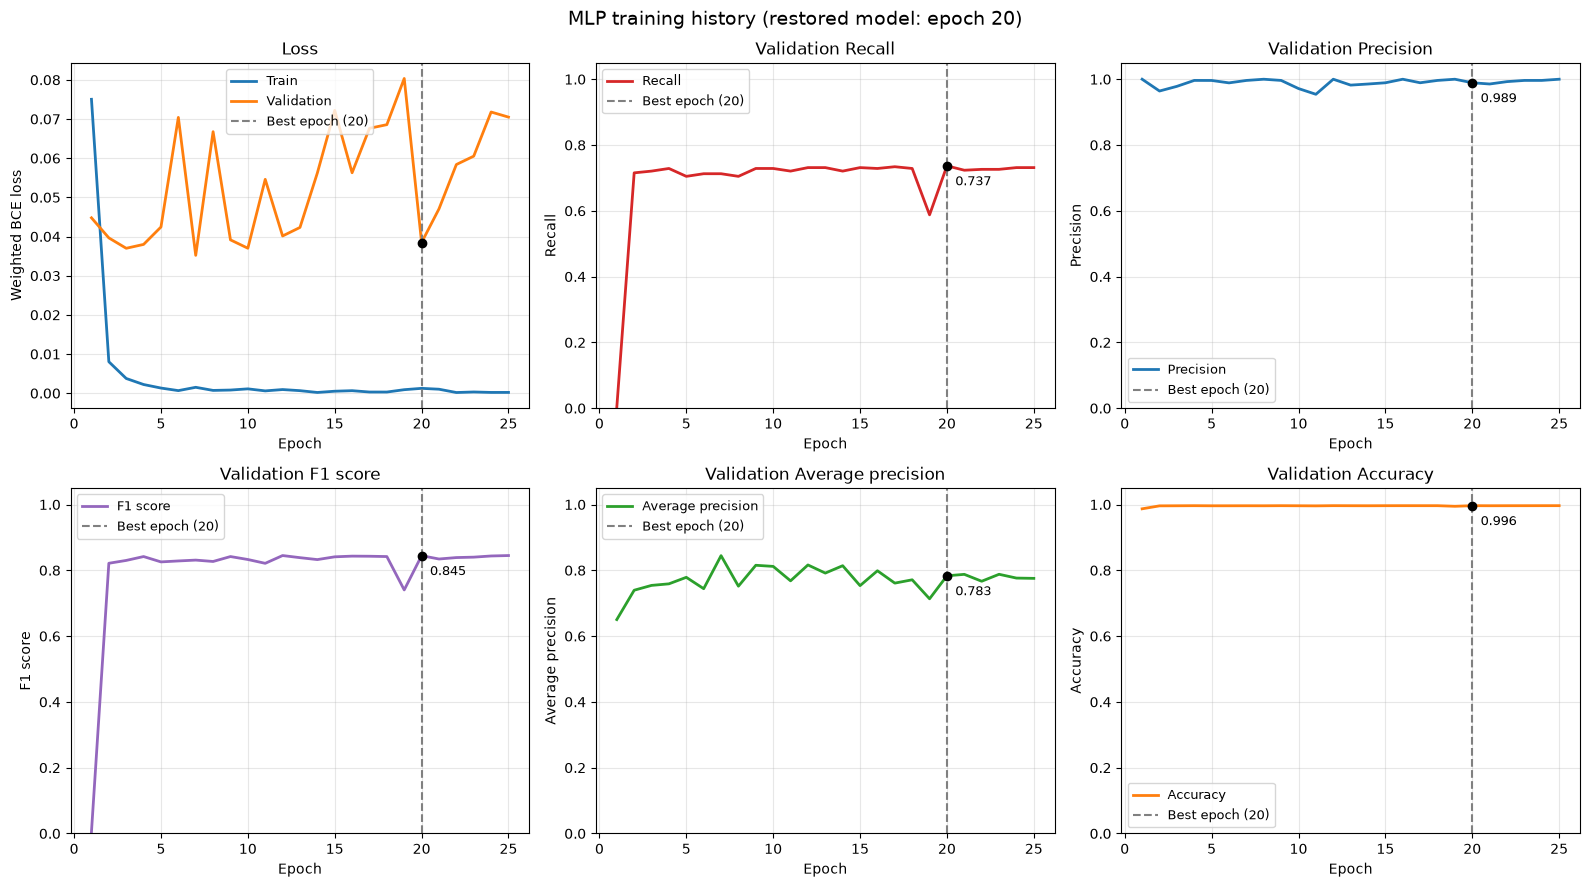

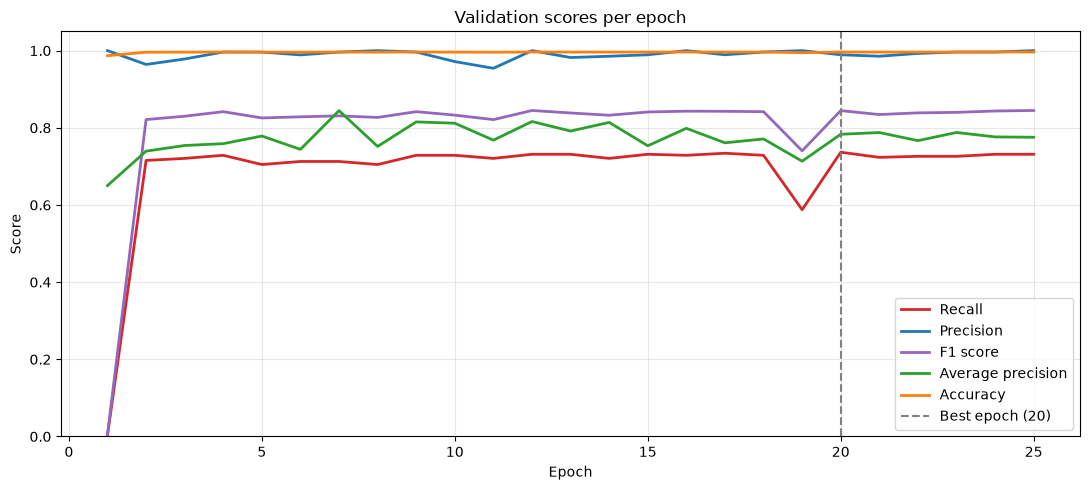

Restored model (epoch 20):
  Recall             0.7367
  Precision          0.9893
  F1 score           0.8445
  Average precision  0.7833
  Accuracy           0.9964


In [ ]:
def plot_history(history, title='MLP training history'):
    epochs = np.arange(1, len(history['train_loss']) + 1)
   
    best_epoch = history.get('best_epoch', int(np.argmin(history['val_loss'])) + 1)
    b = best_epoch - 1   

    score_panels = [
        ('val_recall',    'Recall',            'tab:red'),
        ('val_precision', 'Precision',         'tab:blue'),
        ('val_f1',        'F1 score',          'tab:purple'),
        ('val_ap',        'Average precision', 'tab:green'),
        ('val_accuracy',  'Accuracy',          'tab:orange'),
    ]

    # ================= Figure 1: one panel per metric =================
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes = axes.ravel()

    # ---- panel 1: train vs validation loss ----
    ax = axes[0]
    ax.plot(epochs, history['train_loss'], label='Train', linewidth=2)
    ax.plot(epochs, history['val_loss'],   label='Validation', linewidth=2)
    ax.scatter(best_epoch, history['val_loss'][b], color='black', zorder=5)
    ax.set_title('Loss')
    ax.set_ylabel('Weighted BCE loss')

    # ---- panels 2-6: validation scores ----
    for ax, (key, name, color) in zip(axes[1:], score_panels):
        ax.plot(epochs, history[key], color=color, linewidth=2, label=name)
        ax.scatter(best_epoch, history[key][b], color='black', zorder=5)
        ax.annotate(f'{history[key][b]:.3f}', xy=(best_epoch, history[key][b]),
                    xytext=(6, -14), textcoords='offset points', fontsize=9)
        ax.set_title(f'Validation {name}')
        ax.set_ylabel(name)
        ax.set_ylim(0, 1.05)

    # ---- shared styling ----
    for ax in axes:
        ax.axvline(best_epoch, color='grey', linestyle='--', label=f'Best epoch ({best_epoch})')
        ax.set_xlabel('Epoch')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)

    fig.suptitle(f'{title} (restored model: epoch {best_epoch})', fontsize=14)
    fig.tight_layout()
    plt.show()

    # ================= Figure 2: all scores on one axis =================
    plt.figure(figsize=(11, 5))
    for key, name, color in score_panels:
        plt.plot(epochs, history[key], label=name, color=color, linewidth=2)
    plt.axvline(best_epoch, color='grey', linestyle='--', label=f'Best epoch ({best_epoch})')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.ylim(0, 1.05)
    plt.title('Validation scores per epoch')
    plt.grid(alpha=0.3)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

    # ================= Summary of the restored model =================
    print(f'Restored model (epoch {best_epoch}):')
    for key, name, _ in score_panels:
        print(f'  {name:<18} {history[key][b]:.4f}')

plot_history(mlp_history)

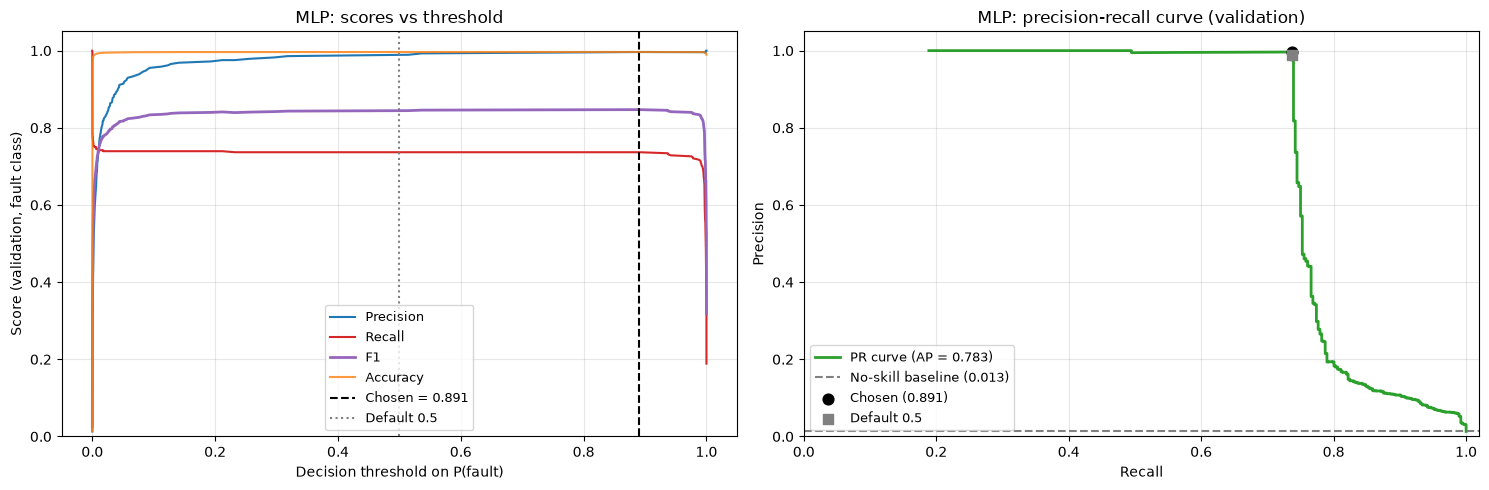

Rule: max F1
                   Precision    Recall        F1  Accuracy
Chosen (0.891)         0.996     0.737     0.847     0.997
Default (0.500)        0.989     0.737     0.845     0.996


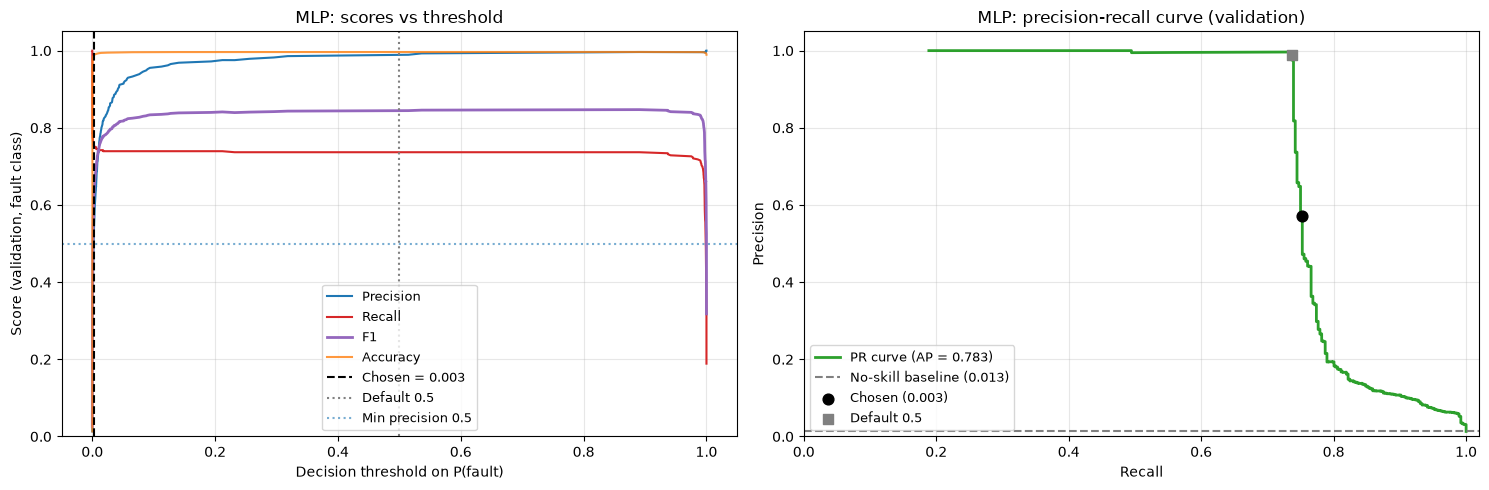

Rule: max recall with precision >= 0.5
                   Precision    Recall        F1  Accuracy
Chosen (0.003)         0.572     0.753     0.650     0.989
Default (0.500)        0.989     0.737     0.845     0.996


In [414]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, average_precision_score

def _scores_at(y_true, prob, t):
  
    pred = prob >= t
    tp = np.sum(pred & (y_true == 1)); fp = np.sum(pred & (y_true == 0))
    fn = np.sum(~pred & (y_true == 1)); tn = np.sum(~pred & (y_true == 0))
    p  = tp / (tp + fp) if (tp + fp) else 0.0
    r  = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) else 0.0
    return {'precision': p, 'recall': r, 'f1': f1, 'accuracy': (tp + tn) / len(y_true)}


def choose_threshold(y_true, prob, title, beta=1.0, min_precision=None):
    
    y_true = np.asarray(y_true).astype(int).ravel()
    prob   = np.asarray(prob, dtype=float).ravel()

   
    fpr, tpr, thr = roc_curve(y_true, prob, drop_intermediate=False)
    keep = np.isfinite(thr) & (thr <= 1.0)           
    fpr, tpr, thr = fpr[keep], tpr[keep], thr[keep]
    order = np.argsort(thr)                            
    fpr, tpr, thr = fpr[order], tpr[order], thr[order]

    n_pos, n_neg = y_true.sum(), len(y_true) - y_true.sum()
    tp, fp = tpr * n_pos, fpr * n_neg
    tn = n_neg - fp
    prec = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    rec  = tpr
    acc  = (tp + tn) / len(y_true)
    b2   = beta ** 2
    fbeta = np.divide((1 + b2) * prec * rec, b2 * prec + rec,
                      out=np.zeros_like(prec), where=(b2 * prec + rec) > 0)
    f_name = 'F1' if beta == 1 else f'F{beta:g}'


    rule = f'max {f_name}'
    i = int(np.argmax(fbeta))
    if min_precision is not None:
        ok = np.where(prec >= min_precision)[0]
        if len(ok):
            i = ok[np.lexsort((prec[ok], rec[ok]))[-1]] 
            rule = f'max recall with precision >= {min_precision:g}'
        else:
            print(f'No threshold reaches precision {min_precision:g}; falling back to max {f_name}.')
    best = float(thr[i])


    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    ax1.plot(thr, prec, label='Precision', color='tab:blue')
    ax1.plot(thr, rec,  label='Recall',    color='tab:red')
    ax1.plot(thr, fbeta, label=f_name,     color='tab:purple', lw=2)
    ax1.plot(thr, acc,  label='Accuracy',  color='tab:orange', alpha=0.8)
    ax1.axvline(best, color='k', ls='--', label=f'Chosen = {best:.3f}')
    ax1.axvline(0.5, color='grey', ls=':', label='Default 0.5')
    if min_precision is not None:
        ax1.axhline(min_precision, color='tab:blue', ls=':', alpha=0.6,
                    label=f'Min precision {min_precision:g}')
    ax1.set_xlabel('Decision threshold on P(fault)')
    ax1.set_ylabel('Score (validation, fault class)')
    ax1.set_title(f'{title}: scores vs threshold')
    ax1.set_ylim(0, 1.05)
    ax1.grid(alpha=0.3)
    ax1.legend(fontsize=9)

    ap = average_precision_score(y_true, prob)
    d  = _scores_at(y_true, prob, 0.5)
    ax2.plot(rec, prec, color='tab:green', lw=2, label=f'PR curve (AP = {ap:.3f})')
    ax2.axhline(n_pos / len(y_true), color='grey', ls='--',
                label=f'No-skill baseline ({n_pos / len(y_true):.3f})')
    ax2.scatter(rec[i], prec[i], color='k', s=60, zorder=5, label=f'Chosen ({best:.3f})')
    ax2.scatter(d['recall'], d['precision'], color='grey', marker='s', s=50, zorder=5,
                label='Default 0.5')
    ax2.set_xlabel('Recall')
    ax2.set_ylabel('Precision')
    ax2.set_title(f'{title}: precision-recall curve (validation)')
    ax2.set_xlim(0, 1.02); ax2.set_ylim(0, 1.05)
    ax2.grid(alpha=0.3)
    ax2.legend(fontsize=9)

    fig.tight_layout()
    plt.show()

   
    c = _scores_at(y_true, prob, best)
    print(f'Rule: {rule}')
    print(f'{"":<18}{"Precision":>10}{"Recall":>10}{"F1":>10}{"Accuracy":>10}')
    for name, s in [(f'Chosen ({best:.3f})', c), ('Default (0.500)', d)]:
        print(f'{name:<18}{s["precision"]:>10.3f}{s["recall"]:>10.3f}'
              f'{s["f1"]:>10.3f}{s["accuracy"]:>10.3f}')
    return best



mlp_threshold = choose_threshold(mlp_val_true, mlp_val_prob, 'MLP')


#mlp_threshold = choose_threshold(mlp_val_true, mlp_val_prob, 'MLP', beta=2)
mlp_threshold = choose_threshold(mlp_val_true, mlp_val_prob, 'MLP', min_precision=0.5)

Confusion counts


,Val (chosen),Val (0.5),Test (chosen),Test (0.5)
Samples,28645,28645,27385,27385
Faulty samples,376,376,310,310
Caught faults (TP),283,277,248,235
Missed faults (FN),93,99,62,75
False alarms (FP),212,3,327,114
Correct healthy (TN),28057,28266,26748,26961


Scores (fault = positive class, chosen threshold = 0.003)


,Val (chosen),Val (0.5),Test (chosen),Test (0.5),Test − Val (chosen)
Threshold,0.0034,0.5000,0.0034,0.5000,0.0000
Recall,0.7527,0.7367,0.8000,0.7581,0.0473
Miss rate (faults missed),0.2473,0.2633,0.2000,0.2419,-0.0473
Precision,0.5717,0.9893,0.4313,0.6734,-0.1404
False alarm rate,0.0075,0.0001,0.0121,0.0042,0.0046
Specificity (healthy),0.9925,0.9999,0.9879,0.9958,-0.0046
NPV (healthy calls correct),0.9967,0.9965,0.9977,0.9972,0.0010
F1,0.6498,0.8445,0.5605,0.7132,-0.0894
MCC,0.6508,0.8521,0.5814,0.7110,-0.0694
Accuracy,0.9894,0.9964,0.9858,0.9931,-0.0036


  Precision                    -0.140
  F1                           -0.089
  MCC                          -0.069
  PR-AUC                       -0.109


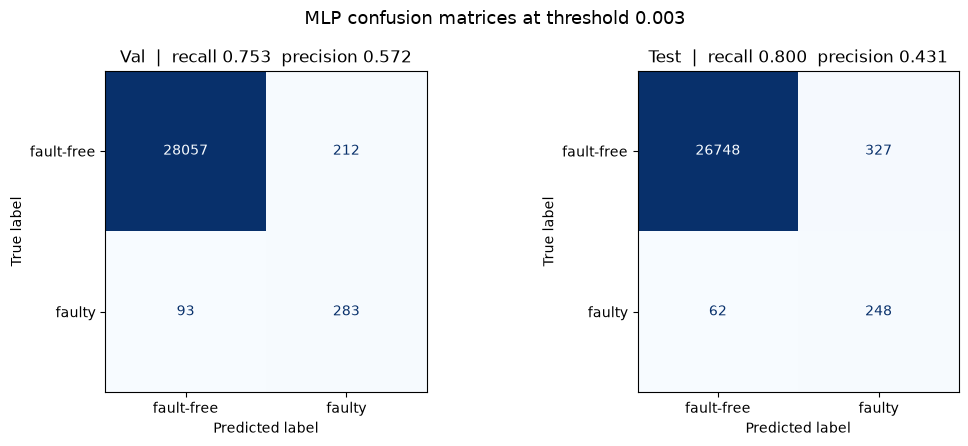

Test classification report (threshold 0.003):
              precision    recall  f1-score   support

  fault-free      0.998     0.988     0.993     27075
      faulty      0.431     0.800     0.560       310

    accuracy                          0.986     27385
   macro avg      0.714     0.894     0.777     27385
weighted avg      0.991     0.986     0.988     27385



In [415]:

from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, balanced_accuracy_score,  
                             precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score)

def _np(x):
    """Accept numpy arrays, pandas objects or torch tensors (CPU or GPU)."""
    if hasattr(x, 'detach'):
        x = x.detach().cpu().numpy()
    return np.asarray(x).ravel()

def _div(a, b):
    return a / b if b else float('nan')                  

COUNT_ROWS = ['Samples', 'Faulty samples', 'Caught faults (TP)', 'Missed faults (FN)',
              'False alarms (FP)', 'Correct healthy (TN)']

def metrics_table(y_true, prob, threshold):
    """All key scores for the fault (positive) class at one threshold."""
    y_true = _np(y_true).astype(int)
    prob   = _np(prob).astype(float)
    y_pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    both_classes = len(np.unique(y_true)) == 2           
    fault_rate = y_true.mean()
    pr_auc = average_precision_score(y_true, prob) if both_classes else float('nan')

    return pd.Series({
    
        'Samples':                      len(y_true),
        'Faulty samples':               tp + fn,
        'Caught faults (TP)':           tp,
        'Missed faults (FN)':           fn,
        'False alarms (FP)':            fp,
        'Correct healthy (TN)':         tn,
       
        'Threshold':                    threshold,
        'Recall':       recall_score(y_true, y_pred, zero_division=0),
        'Miss rate (faults missed)':    _div(fn, fn + tp),
        'Precision':                        precision_score(y_true, y_pred, zero_division=0),
        'False alarm rate':             _div(fp, fp + tn),
        'Specificity (healthy)':        _div(tn, tn + fp),
        'NPV (healthy calls correct)':  _div(tn, tn + fn),
        'F1':                           f1_score(y_true, y_pred, zero_division=0),
        'MCC':                          matthews_corrcoef(y_true, y_pred),
        'Accuracy':                     accuracy_score(y_true, y_pred),
        'Balanced accuracy':            balanced_accuracy_score(y_true, y_pred),
      
        'ROC-AUC':                      roc_auc_score(y_true, prob) if both_classes else float('nan'),
        'PR-AUC':                       pr_auc,
        'Fault rate (PR-AUC baseline)': fault_rate,
        'PR-AUC lift over baseline':    _div(pr_auc, fault_rate),
    })


evaluations = {
    'Val (chosen)':  (mlp_val_true,  mlp_val_prob,  mlp_threshold),
    'Val (0.5)':     (mlp_val_true,  mlp_val_prob,  0.5),
    'Test (chosen)': (mlp_test_true, mlp_test_prob, mlp_threshold),
    'Test (0.5)':    (mlp_test_true, mlp_test_prob, 0.5),
}
mlp_metrics = pd.DataFrame({name: metrics_table(*args) for name, args in evaluations.items()})

mlp_counts = mlp_metrics.loc[COUNT_ROWS].astype(int)
mlp_scores = mlp_metrics.drop(index=COUNT_ROWS)
mlp_scores['Test − Val (chosen)'] = mlp_scores['Test (chosen)'] - mlp_scores['Val (chosen)']

print('Confusion counts')
display(mlp_counts)
print(f'Scores (fault = positive class, chosen threshold = {mlp_threshold:.3f})')
display(mlp_scores.round(4))


gap_rows = ['Recall', 'Precision', 'F1', 'MCC', 'PR-AUC']
big_gaps = mlp_scores.loc[gap_rows, 'Test − Val (chosen)']
big_gaps = big_gaps[big_gaps < -0.05]
if len(big_gaps):
    print('Warning: these scores drop by more than 0.05 from validation to test:')
    for name, gap in big_gaps.items():
        print(f'  {name:<28} {gap:+.3f}')
else:
    print('Validation and test scores are consistent (no drop larger than 0.05).')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, split in zip(axes, ['Val (chosen)', 'Test (chosen)']):
    y_true, prob, thr = evaluations[split]
    y_true, prob = _np(y_true).astype(int), _np(prob).astype(float)
    ConfusionMatrixDisplay.from_predictions(
        y_true, (prob >= thr).astype(int), labels=[0, 1],
        display_labels=['fault-free', 'faulty'], values_format='d',
        cmap='Blues', colorbar=False, ax=ax)
    s = mlp_scores[split]
    ax.set_title(f'{split.split()[0]}  |  recall {s["Recall"]:.3f}  '
                 f'precision {s["Precision"]:.3f}')
fig.suptitle(f'MLP confusion matrices at threshold {mlp_threshold:.3f}', fontsize=13)
fig.tight_layout()
plt.show()


mlp_test_true_np = _np(mlp_test_true).astype(int)
mlp_test_pred = (_np(mlp_test_prob) >= mlp_threshold).astype(int)   
print(f'Test classification report (threshold {mlp_threshold:.3f}):')
print(classification_report(mlp_test_true_np, mlp_test_pred,
                            target_names=['fault-free', 'faulty'], digits=3, zero_division=0))

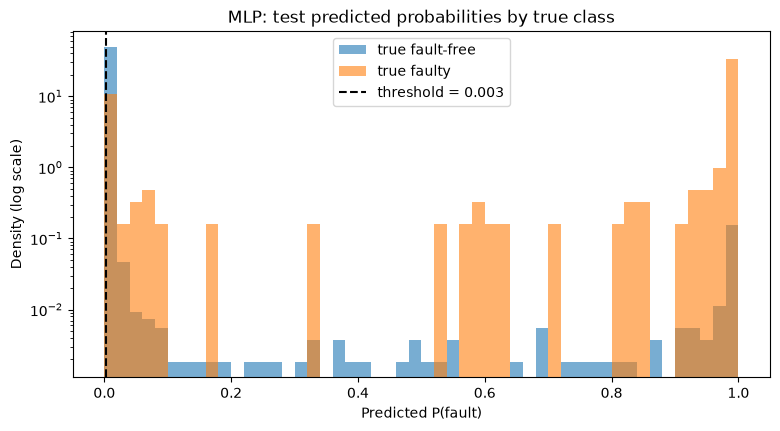

In [416]:
def plot_prob_hist(y_true, prob, threshold, title):
    """How well the predicted probabilities separate the two classes."""
    plt.figure(figsize=(9, 4.5))
    bins = np.linspace(0, 1, 51)
    plt.hist(prob[y_true == 0], bins=bins, alpha=0.6, label='true fault-free', density=True)
    plt.hist(prob[y_true == 1], bins=bins, alpha=0.6, label='true faulty', density=True)
    plt.axvline(threshold, color='k', ls='--', label=f'threshold = {threshold:.3f}')
    plt.yscale('log')
    plt.xlabel('Predicted P(fault)')
    plt.ylabel('Density (log scale)')
    plt.title(title)
    plt.legend()
    plt.show()

plot_prob_hist(mlp_test_true, mlp_test_prob, mlp_threshold, 'MLP: test predicted probabilities by true class')

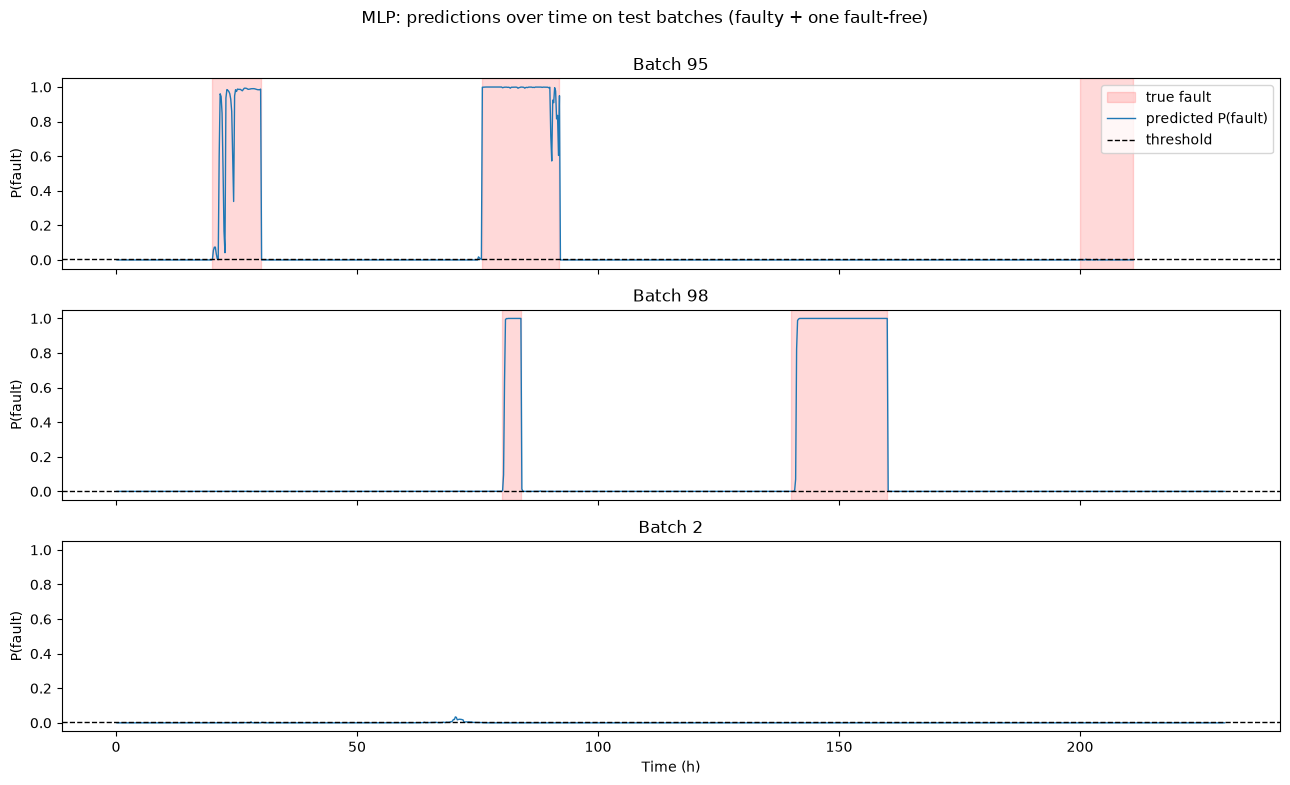

In [417]:
def plot_batch_predictions(meta, prob, threshold, batches, title):
 
    d = meta.assign(prob=prob)
    fig, axes = plt.subplots(len(batches), 1, figsize=(13, 2.6 * len(batches)), sharex=True, squeeze=False)
    for ax, b in zip(axes[:, 0], batches):
        g = d[d[batch_col] == b]
        ax.fill_between(g[time_col], 0, 1, where=g[faulty_col] == 1, color='red', alpha=0.15,
                        label='true fault', transform=ax.get_xaxis_transform())
        ax.plot(g[time_col], g['prob'], lw=1, label='predicted P(fault)')
        ax.axhline(threshold, color='k', ls='--', lw=1, label='threshold')
        ax.set(ylim=(-0.05, 1.05), ylabel='P(fault)', title=f'Batch {b}')
    axes[0, 0].legend(loc='upper right')
    axes[-1, 0].set_xlabel('Time (h)')
    fig.suptitle(title, y=1.0)
    plt.tight_layout()
    plt.show()

test_faulty_batches  = sorted(set(test_batches) & set(faulty_batches))
test_healthy_example = sorted(set(test_batches) & set(healthy_batches))[:1]
plot_batch_predictions(mlp_test_meta, mlp_test_prob, mlp_threshold,
                       test_faulty_batches + test_healthy_example,
                       'MLP: predictions over time on test batches (faulty + one fault-free)')

**LSTM**

In [418]:

def weightedBCE(labels):
  num_pos = float(labels.sum())
  num_neg = float(labels.numel() - num_pos)
  if num_pos == 0:
    raise ValueError("No faulty samples in the labels split.")
  weight_val = num_neg / num_pos
  pos_weight = torch.tensor([weight_val], device=DEVICE)
  print(f"faulty: {int(num_pos)} | healthy: {int(num_neg)} | pos_weight:"f" {weight_val:.4f}")
  return nn.BCEWithLogitsLoss(pos_weight=pos_weight)

In [419]:
loss_fn_lstm = nn.BCEWithLogitsLoss()


WINDOW = 40   # 40 steps x 0.2 h = 8 hours of sensor history per sample
STRIDE = 1    # 1 = a window ending at every time step

class BatchWindowDataset(Dataset):
    """Sliding windows that never cross from one batch into the next.
    Sample = the last WINDOW time steps, label = fault flag at the window's last step."""
    def __init__(self, data, window=WINDOW, stride=STRIDE):
        self.window = window
        self.X, self.y, self.index, meta = [], [], [], []
        for _, d in data.groupby(batch_col, sort=False):
            k = len(self.X)
            self.X.append(torch.tensor(d[feature_cols].to_numpy(), dtype=torch.float32))
            self.y.append(torch.tensor(d[faulty_col].to_numpy(), dtype=torch.float32))
            ends = list(range(window, len(d) + 1, stride))
            self.index += [(k, e) for e in ends]
            # batch / time / label of the last step of every window (for plots)
            meta.append(d.iloc[[e - 1 for e in ends]][[batch_col, time_col, faulty_col]])
        self.meta = pd.concat(meta).reset_index(drop=True)

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        k, e = self.index[i]
        return self.X[k][e - self.window:e], self.y[k][e - 1]

lstm_train_ds = BatchWindowDataset(train_df)
lstm_val_ds   = BatchWindowDataset(val_df)
lstm_test_ds  = BatchWindowDataset(test_df)

g_lstm = torch.Generator().manual_seed(SEED)
lstm_train_loader = DataLoader(lstm_train_ds, batch_size=batch_size, shuffle=True, generator=g_lstm)
lstm_val_loader   = DataLoader(lstm_val_ds,   batch_size=batch_size, shuffle=False)
lstm_test_loader  = DataLoader(lstm_test_ds,  batch_size=batch_size, shuffle=False)

print('LSTM train:')

lstm_criterion = loss_fn_lstm



#lstm_wtloss = weightedBCE(torch.tensor(lstm_train_ds.meta[faulty_col].to_numpy(), dtype=torch.float32))


print('Windows: train', len(lstm_train_ds), '| val', len(lstm_val_ds), '| test', len(lstm_test_ds))
xb, yb = next(iter(lstm_train_loader))
print('One batch:', tuple(xb.shape), tuple(yb.shape))   

LSTM train:
Windows: train 55916 | val 27670 | test 26449
One batch: (512, 40, 23) (512,)


In [420]:
class LSTMClassifier(nn.Module):
    def __init__(self, n_in, hidden=45, num_layers=1, dropout=0.11):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 1))   

    def forward(self, x):               
        out, _ = self.lstm(x)             
        return self.head(out[:, -1]).squeeze(-1)   

lstm = LSTMClassifier(n_in=len(feature_cols)).to(DEVICE)
print(lstm)
print('Trainable parameters:', sum(p.numel() for p in lstm.parameters() if p.requires_grad))

LSTMClassifier(
  (lstm): LSTM(23, 45, batch_first=True)
  (head): Sequential(
    (0): Dropout(p=0.11, inplace=False)
    (1): Linear(in_features=45, out_features=1, bias=True)
  )
)
Trainable parameters: 12646


In [421]:
import time
torch.manual_seed(SEED)
lstm = LSTMClassifier(n_in=len(feature_cols)).to(DEVICE)

t0 = time.time()

#unweighted loss
#lstm_history = fit(lstm, lstm_train_loader, lstm_val_loader, loss_fn_lstm,
 #                  epochs=50, lr=0.0026, patience=5)

#weighted

lstm_history = fit(lstm, lstm_train_loader, lstm_val_loader, loss_fn_lstm,   
                   epochs=50, lr=0.01, patience=5)


print(f'Training time: {(time.time() - t0) / 60:.1f} min')

epoch   1 | train loss 0.0551 | val loss 0.0318 | AP 0.6442 | val precision 0.8400 | val accuracy 0.9901 | val recall 0.3351 | val f1 0.4791
epoch   5 | train loss 0.0021 | val loss 0.0350 | AP 0.7206 | val precision 0.8859 | val accuracy 0.9947 | val recall 0.7021 | val f1 0.7834
epoch  10 | train loss 0.0007 | val loss 0.0301 | AP 0.8197 | val precision 0.9210 | val accuracy 0.9953 | val recall 0.7128 | val f1 0.8036
epoch  15 | train loss 0.0006 | val loss 0.0528 | AP 0.7125 | val precision 0.6142 | val accuracy 0.9900 | val recall 0.7154 | val f1 0.6609
epoch  20 | train loss 0.0002 | val loss 0.0417 | AP 0.8209 | val precision 0.7396 | val accuracy 0.9927 | val recall 0.7101 | val f1 0.7246
Early stopping at epoch 21.
Restored best model from epoch 16 (val recall 0.718, val AP 0.822), f1 score 0.713
Training time: 0.3 min


In [422]:
_, lstm_val_prob,  lstm_val_true  = run_epoch(lstm, lstm_val_loader,  lstm_criterion)
_, lstm_test_prob, lstm_test_true = run_epoch(lstm, lstm_test_loader, lstm_criterion)
lstm_test_meta = lstm_test_ds.meta
print('Validation predictions:', lstm_val_prob.shape, '| Test predictions:', lstm_test_prob.shape)

Validation predictions: (27670,) | Test predictions: (26449,)


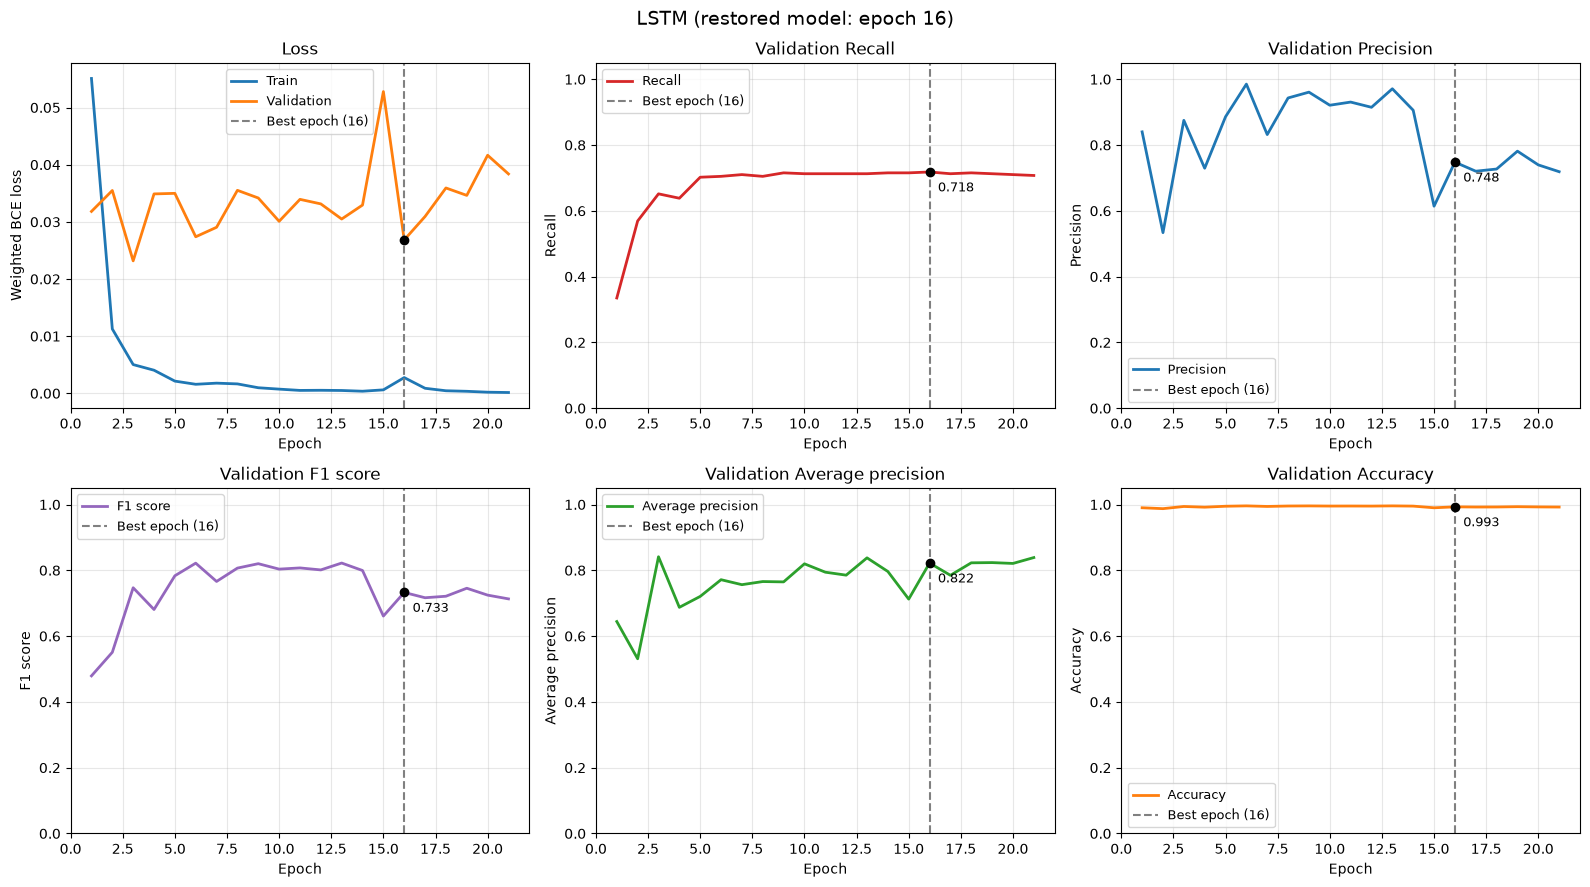

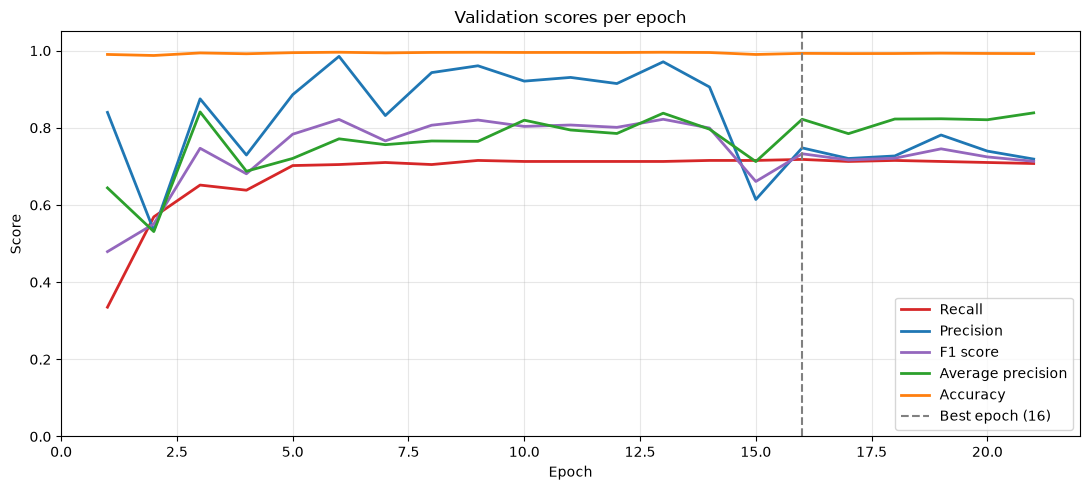

Restored model (epoch 16):
  Recall             0.7181
  Precision          0.7479
  F1 score           0.7327
  Average precision  0.8221
  Accuracy           0.9929


In [423]:
plot_history(lstm_history, 'LSTM')

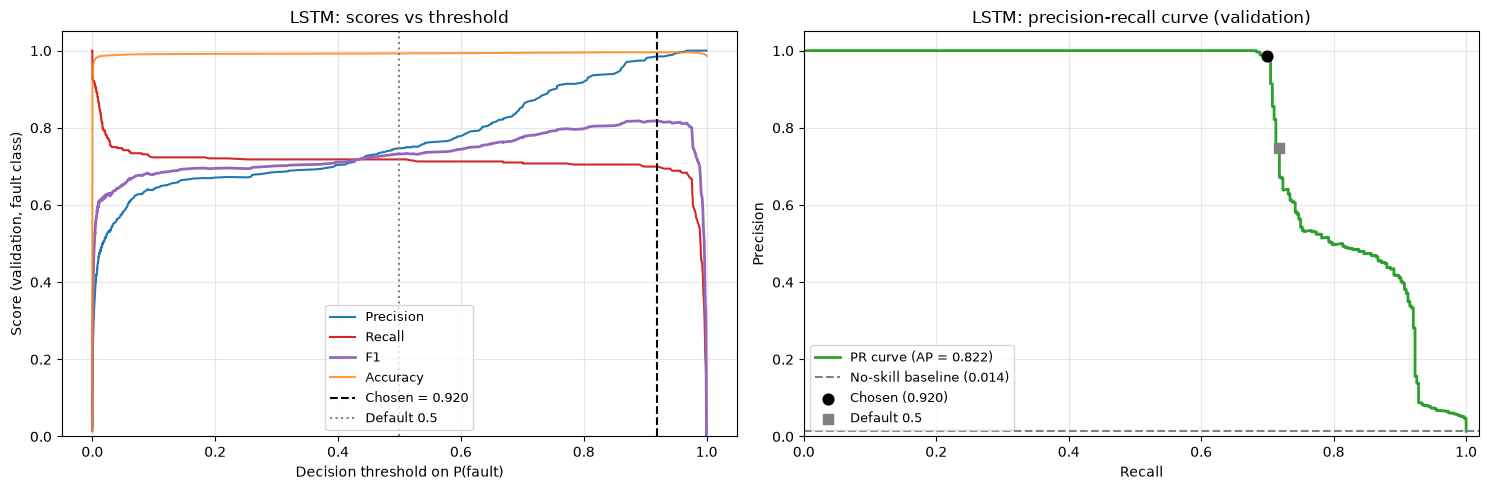

Rule: max F1
                   Precision    Recall        F1  Accuracy
Chosen (0.920)         0.985     0.699     0.818     0.996
Default (0.500)        0.748     0.718     0.733     0.993


In [424]:
lstm_threshold = choose_threshold(lstm_val_true, lstm_val_prob, 'LSTM')

In [425]:
lstm_metrics = pd.DataFrame({
    'Validation': metrics_table(lstm_val_true,  lstm_val_prob,  lstm_threshold),
    'Test':       metrics_table(lstm_test_true, lstm_test_prob, lstm_threshold),
})
display(lstm_metrics.round(4))

lstm_test_pred = (lstm_test_prob >= lstm_threshold).astype(int)
print(f'Test classification report (threshold {lstm_threshold:.3f}):')
print(classification_report(lstm_test_true, lstm_test_pred,
                            target_names=['fault-free', 'faulty'], digits=3))

,Validation,Test
Samples,27670.0000,26449.0000
Faulty samples,376.0000,310.0000
Caught faults (TP),263.0000,232.0000
Missed faults (FN),113.0000,78.0000
False alarms (FP),4.0000,1.0000
Correct healthy (TN),27290.0000,26138.0000
Threshold,0.9196,0.9196
Recall,0.6995,0.7484
Miss rate (faults missed),0.3005,0.2516
Precision,0.9850,0.9957


Test classification report (threshold 0.920):
              precision    recall  f1-score   support

  fault-free      0.997     1.000     0.998     26139
      faulty      0.996     0.748     0.855       310

    accuracy                          0.997     26449
   macro avg      0.996     0.874     0.927     26449
weighted avg      0.997     0.997     0.997     26449



LSTM: test confusion matrix (threshold 0.920)
  Faults caught:  232 / 310  (recall 0.748)
  Faults missed:  78
  False alarms:   1 / 26,139  (false alarm rate 0.000)
  Alarm precision: 0.996


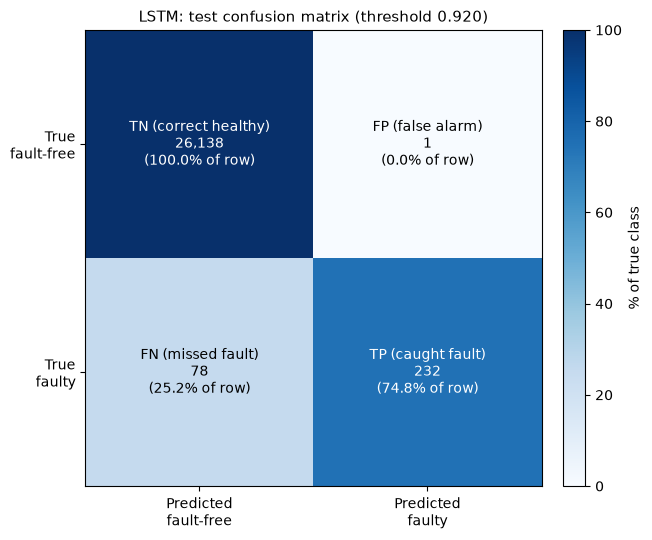

In [426]:


def plot_confusion(y_true, y_pred, title, class_names=('fault-free', 'faulty'), ax=None):
    """Confusion matrix with counts and row percentages (fault = positive class)."""
    y_true = _np(y_true).astype(int)
    y_pred = _np(y_pred).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    row_pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100   # % of each TRUE class

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(6.5, 5.5))

    # colour by row percentage, so the rare faulty row is as readable as the healthy row
    im = ax.imshow(row_pct, cmap='Blues', vmin=0, vmax=100)
    cell_names = [['TN (correct healthy)', 'FP (false alarm)'],
                  ['FN (missed fault)',    'TP (caught fault)']]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cell_names[i][j]}\n{cm[i, j]:,}\n({row_pct[i, j]:.1f}% of row)',
                    ha='center', va='center', fontsize=10,
                    color='white' if row_pct[i, j] > 50 else 'black')

    ax.set_xticks([0, 1]); ax.set_xticklabels([f'Predicted\n{c}' for c in class_names])
    ax.set_yticks([0, 1]); ax.set_yticklabels([f'True\n{c}' for c in class_names])
    ax.set_title(title, fontsize=11)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='% of true class')

    tn, fp, fn, tp = cm.ravel()
    print(f'{title}')
    print(f'  Faults caught:  {tp:,} / {tp + fn:,}  (recall {tp / max(tp + fn, 1):.3f})')
    print(f'  Faults missed:  {fn:,}')
    print(f'  False alarms:   {fp:,} / {fp + tn:,}  (false alarm rate {fp / max(fp + tn, 1):.3f})')
    print(f'  Alarm precision: {tp / max(tp + fp, 1):.3f}')

    if standalone:
        plt.tight_layout()
        plt.show()
    return cm


lstm_cm = plot_confusion(lstm_test_true, lstm_test_pred,
                         f'LSTM: test confusion matrix (threshold {lstm_threshold:.3f})')

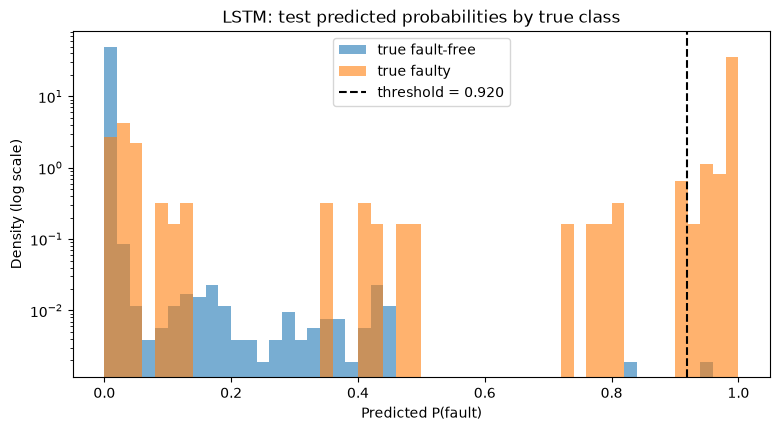

In [427]:
plot_prob_hist(lstm_test_true, lstm_test_prob, lstm_threshold, 'LSTM: test predicted probabilities by true class')

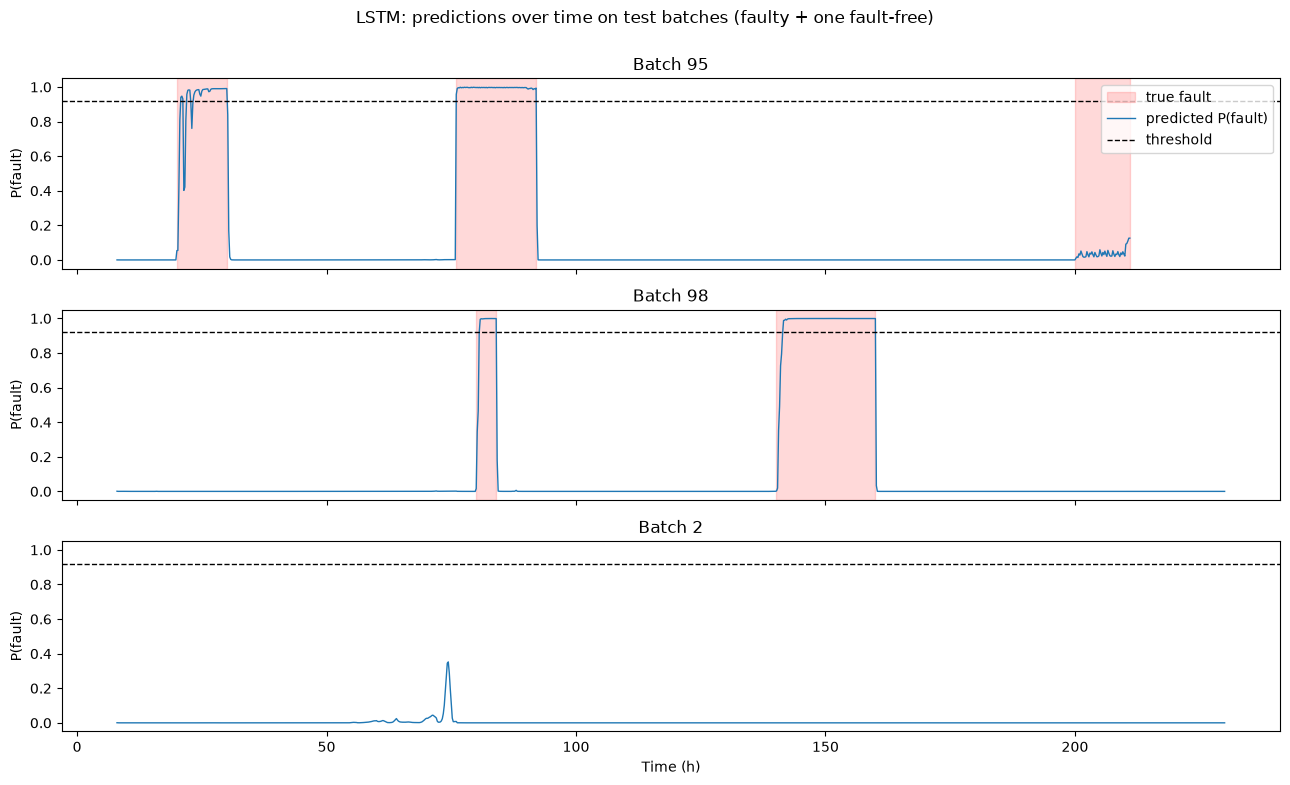

In [428]:
plot_batch_predictions(lstm_test_meta, lstm_test_prob, lstm_threshold,
                       test_faulty_batches + test_healthy_example,
                       'LSTM: predictions over time on test batches (faulty + one fault-free)')

**LSTM-FCN**

In [429]:
class LSTMFCN(nn.Module):
    def __init__(self, n_in, window=WINDOW, hidden=60, lstm_dropout=0.64,
                 filters=(128, 256, 128), kernels=(11, 7, 5), dim_shuffle=False):
        super().__init__()
        self.dim_shuffle = dim_shuffle
       
        self.lstm = nn.LSTM(window if dim_shuffle else n_in, hidden, batch_first=True)
        self.lstm_drop = nn.Dropout(lstm_dropout)
        
        layers, c = [], n_in
        for f, k in zip(filters, kernels):
            layers += [nn.Conv1d(c, f, k, padding='same'), nn.BatchNorm1d(f), nn.ReLU()]
            c = f
        self.fcn = nn.Sequential(*layers)
        self.head = nn.Linear(hidden + filters[-1], 1)

    def forward(self, x):                             
        lstm_in = x.transpose(1, 2) if self.dim_shuffle else x
        out, _ = self.lstm(lstm_in)
        h = self.lstm_drop(out[:, -1])                      
        c = self.fcn(x.transpose(1, 2)).mean(dim=-1)        
        return self.head(torch.cat([h, c], dim=1)).squeeze(-1)

torch.manual_seed(SEED)
lstm_fcn = LSTMFCN(n_in=len(feature_cols)).to(DEVICE)
print(lstm_fcn)
print('Trainable parameters:', sum(p.numel() for p in lstm_fcn.parameters() if p.requires_grad))



LSTMFCN(
  (lstm): LSTM(23, 60, batch_first=True)
  (lstm_drop): Dropout(p=0.64, inplace=False)
  (fcn): Sequential(
    (0): Conv1d(23, 128, kernel_size=(11,), stride=(1,), padding=same)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(128, 256, kernel_size=(7,), stride=(1,), padding=same)
    (4): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv1d(256, 128, kernel_size=(5,), stride=(1,), padding=same)
    (7): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
  )
  (head): Linear(in_features=188, out_features=1, bias=True)
)
Trainable parameters: 447725


In [430]:
t0 = time.time()

lstm_fcn_history = fit(lstm_fcn, lstm_train_loader, lstm_val_loader, loss_fn_lstm,
#                       epochs=50, lr=0.0032, patience=5)

# weighted loss

#lstm_fcn_history = fit(lstm_fcn, lstm_train_loader, lstm_val_loader, lstm_wtloss,
                       epochs=50, lr=0.0032, patience=5)

print(f'Training time: {(time.time() - t0) / 60:.1f} min')




epoch   1 | train loss 0.0578 | val loss 0.0328 | AP 0.6272 | val precision 0.8916 | val accuracy 0.9922 | val recall 0.4814 | val f1 0.6252
epoch   5 | train loss 0.0025 | val loss 0.0234 | AP 0.8182 | val precision 0.9560 | val accuracy 0.9954 | val recall 0.6941 | val f1 0.8043
epoch  10 | train loss 0.0011 | val loss 0.0338 | AP 0.7665 | val precision 0.9852 | val accuracy 0.9959 | val recall 0.7074 | val f1 0.8235
Early stopping at epoch 13.
Restored best model from epoch 8 (val recall 0.707, val AP 0.816), f1 score 0.820
Training time: 0.4 min


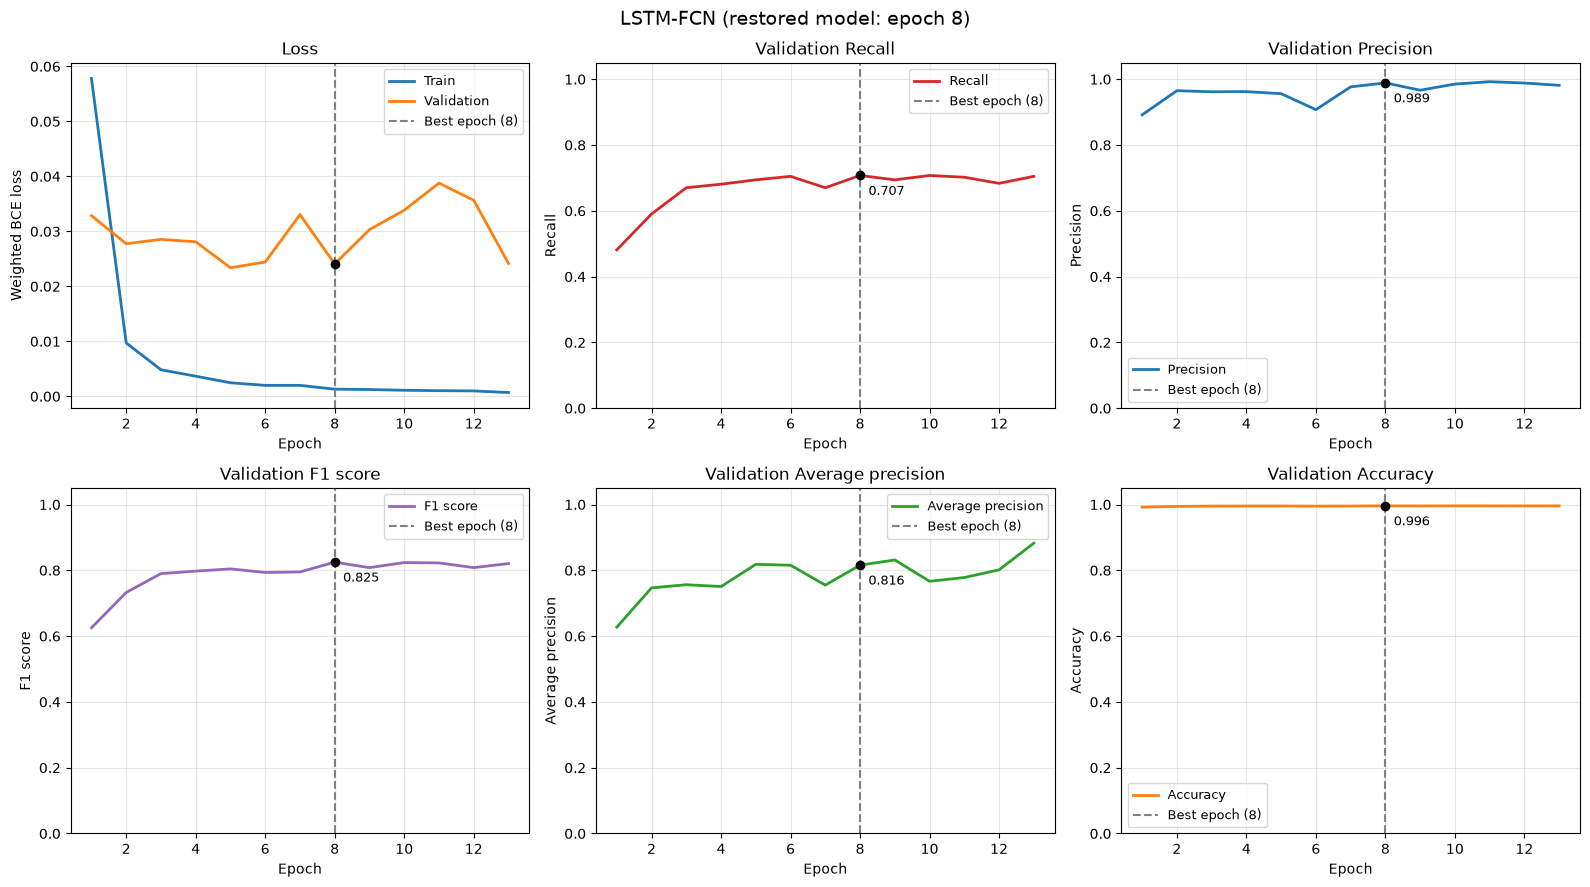

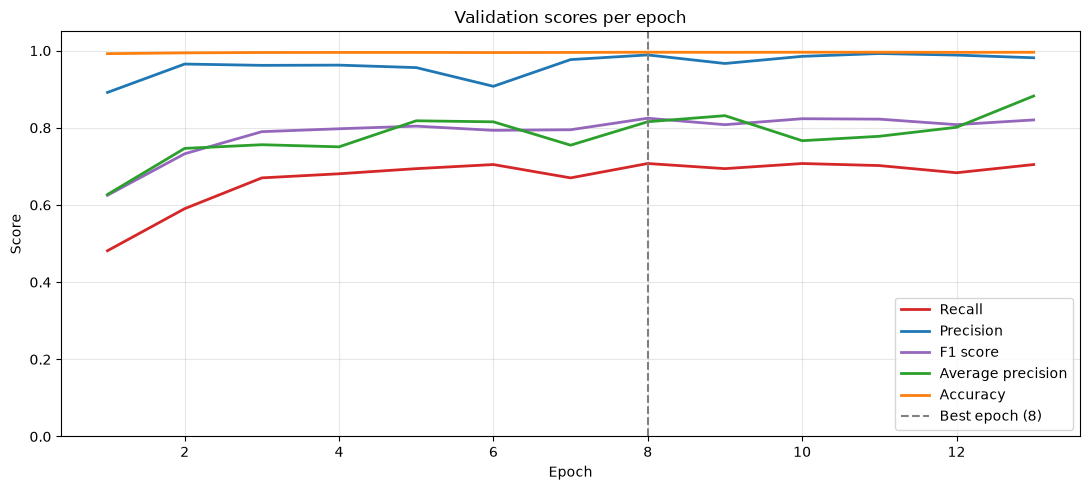

Restored model (epoch 8):
  Recall             0.7074
  Precision          0.9888
  F1 score           0.8248
  Average precision  0.8157
  Accuracy           0.9959


In [431]:
plot_history(lstm_fcn_history, 'LSTM-FCN')

**MLP/LSTM/LSTM-FCN**

In [432]:

from sklearn.metrics import precision_recall_curve

# Predictions from the trained LSTM-FCN (same loaders as the LSTM)
_, lstm_fcn_val_prob,  lstm_fcn_val_true  = run_epoch(lstm_fcn, lstm_val_loader,  lstm_criterion)
_, lstm_fcn_test_prob, lstm_fcn_test_true = run_epoch(lstm_fcn, lstm_test_loader, lstm_criterion)

# Threshold chosen on validation. For a fair comparison, use the SAME method
# you used to get lstm_threshold / mlp_threshold. F1-optimal shown as a fallback:
prec, rec, thr = precision_recall_curve(lstm_fcn_val_true, lstm_fcn_val_prob)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
lstm_fcn_threshold = thr[np.argmax(f1[:-1])]
print(f'LSTM-FCN threshold: {lstm_fcn_threshold:.4f}')

LSTM-FCN threshold: 0.7051


Test set, same 26449 time steps for all three models


,MLP,LSTM,LSTM-FCN,LSTM - MLP,LSTM-FCN - MLP,LSTM-FCN - LSTM
Samples,26449.0000,26449.0000,26449.0000,0.0000,0.0000,0.0000
Faulty samples,310.0000,310.0000,310.0000,0.0000,0.0000,0.0000
Caught faults (TP),248.0000,232.0000,216.0000,-16.0000,-32.0000,-16.0000
Missed faults (FN),62.0000,78.0000,94.0000,16.0000,32.0000,16.0000
False alarms (FP),327.0000,1.0000,1.0000,-326.0000,-326.0000,0.0000
Correct healthy (TN),25812.0000,26138.0000,26138.0000,326.0000,326.0000,0.0000
Threshold,0.0034,0.9196,0.7051,0.9162,0.7017,-0.2145
Recall,0.8000,0.7484,0.6968,-0.0516,-0.1032,-0.0516
Miss rate (faults missed),0.2000,0.2516,0.3032,0.0516,0.1032,0.0516
Precision,0.4313,0.9957,0.9954,0.5644,0.5641,-0.0003


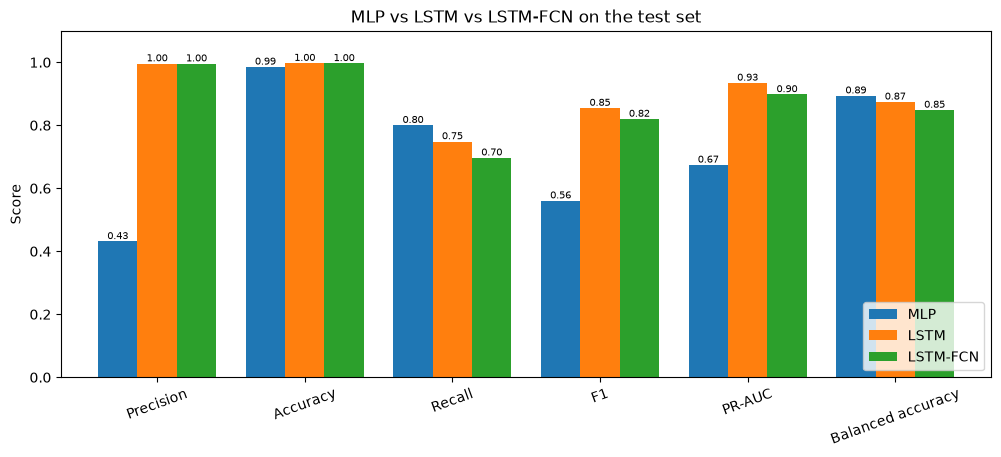

In [433]:
cmp = (lstm_test_meta
       .assign(lstm_prob=lstm_test_prob, lstm_fcn_prob=lstm_fcn_test_prob)
       .merge(mlp_test_meta.assign(mlp_prob=mlp_test_prob)[[batch_col, time_col, 'mlp_prob']],
              on=[batch_col, time_col], how='left'))
assert cmp[['mlp_prob', 'lstm_fcn_prob']].notna().all().all()
cmp_true = cmp[faulty_col].to_numpy()

comparison = pd.DataFrame({
    'MLP':      metrics_table(cmp_true, cmp['mlp_prob'].to_numpy(),      mlp_threshold),
    'LSTM':     metrics_table(cmp_true, cmp['lstm_prob'].to_numpy(),     lstm_threshold),
    'LSTM-FCN': metrics_table(cmp_true, cmp['lstm_fcn_prob'].to_numpy(), lstm_fcn_threshold),
})
comparison['LSTM - MLP']      = comparison['LSTM']     - comparison['MLP']
comparison['LSTM-FCN - MLP']  = comparison['LSTM-FCN'] - comparison['MLP']
comparison['LSTM-FCN - LSTM'] = comparison['LSTM-FCN'] - comparison['LSTM']
print(f'Test set, same {len(cmp)} time steps for all three models')
display(comparison.round(4))

# Bar chart of the most important scores
key = ['Precision', 'Accuracy', 'Recall',
       'F1', 'PR-AUC', 'Balanced accuracy']

ax = comparison.loc[key, ['MLP', 'LSTM', 'LSTM-FCN']].plot.bar(figsize=(12, 4.5), rot=20, width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=7)
ax.set(ylim=(0, 1.1), ylabel='Score', title='MLP vs LSTM vs LSTM-FCN on the test set')
ax.legend(loc='lower right')

In [437]:
SEEDS = [520, 42, 121]

def set_seed(seed):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# Set initial default seed
set_seed(SEEDS[0])
torch.set_num_threads(1)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)

PyTorch: 2.11.0+cu128
Device: cuda


In [438]:
cmp = (lstm_test_meta
       .assign(lstm_prob=lstm_test_prob, lstm_fcn_prob=lstm_fcn_test_prob)
       .merge(mlp_test_meta.assign(mlp_prob=mlp_test_prob)[[batch_col, time_col, 'mlp_prob']],
              on=[batch_col, time_col], how='left'))
assert cmp[['mlp_prob', 'lstm_fcn_prob']].notna().all().all()
cmp_true = cmp[faulty_col].to_numpy()


In [439]:
from sklearn.metrics import precision_recall_curve


def best_f1_threshold(y_true, prob):
    prec, rec, thr = precision_recall_curve(y_true, prob)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[np.argmax(f1[:-1])])


def run_model(make_model, train_loader, val_loader, test_loader, seed, epochs, patience):
    set_seed(seed)                                 
    model = make_model().to(DEVICE)
    g = torch.Generator().manual_seed(seed)
    seeded_train_loader = DataLoader(train_loader.dataset, batch_size=train_loader.batch_size,
                                     shuffle=True, generator=g)

    fit(model, seeded_train_loader, val_loader, loss_fn,
        epochs=epochs, lr=1e-3, patience=patience)  

    _, val_prob, val_true = run_epoch(model, val_loader, loss_fn)
    _, test_prob, _       = run_epoch(model, test_loader, loss_fn)
    return test_prob, val_prob, best_f1_threshold(val_true, val_prob)   


def run_mlp(seed):
    return run_model(lambda: MLP(n_in=len(feature_cols)),
                     mlp_train_loader, mlp_val_loader, mlp_test_loader,
                     seed, epochs=100, patience=5)        

def run_lstm(seed):
    return run_model(lambda: LSTMClassifier(n_in=len(feature_cols)),
                     lstm_train_loader, lstm_val_loader, lstm_test_loader,
                     seed, epochs=50, patience=5)


def run_lstm_fcn(seed):
    
    return run_model(lambda: LSTMFCN(n_in=len(feature_cols)),
                     lstm_train_loader, lstm_val_loader, lstm_test_loader,
                     seed, epochs=50, patience=5)

In [440]:
key = ['Precision', 'Accuracy', 'Recall',
       'F1', 'PR-AUC', 'Balanced accuracy']

mlp_val_meta  = val_df[[batch_col, time_col, faulty_col]].reset_index(drop=True)
lstm_val_meta = lstm_val_loader.dataset.meta


def compare_models(lstm_meta, mlp_meta, mlp_prob, lstm_prob, fcn_prob, thr):

    c = (lstm_meta
         .assign(lstm_prob=lstm_prob, lstm_fcn_prob=fcn_prob)
         .merge(mlp_meta.assign(mlp_prob=mlp_prob)[[batch_col, time_col, 'mlp_prob']],
                on=[batch_col, time_col], how='left'))
    assert c[['mlp_prob', 'lstm_fcn_prob']].notna().all().all()
    y = c[faulty_col].to_numpy()
    return pd.DataFrame({
        'MLP':      metrics_table(y, c['mlp_prob'].to_numpy(),      thr['MLP']),
        'LSTM':     metrics_table(y, c['lstm_prob'].to_numpy(),     thr['LSTM']),
        'LSTM-FCN': metrics_table(y, c['lstm_fcn_prob'].to_numpy(), thr['LSTM-FCN']),
    }).loc[key]


seed_results, seed_results_val = [], []        
for seed in SEEDS:
    print(f'--- Running Seed: {seed} ---')
    s_mlp_test,  s_mlp_val,  s_mlp_thr  = run_mlp(seed)        
    s_lstm_test, s_lstm_val, s_lstm_thr = run_lstm(seed)
    s_fcn_test,  s_fcn_val,  s_fcn_thr  = run_lstm_fcn(seed)
    thr = {'MLP': s_mlp_thr, 'LSTM': s_lstm_thr, 'LSTM-FCN': s_fcn_thr}

    seed_results.append(compare_models(lstm_test_meta, mlp_test_meta,
                                       s_mlp_test, s_lstm_test, s_fcn_test, thr))
    seed_results_val.append(compare_models(lstm_val_meta, mlp_val_meta,     
                                           s_mlp_val, s_lstm_val, s_fcn_val, thr))
    print('Val F1:', seed_results_val[-1].loc['F1'].round(3).to_dict(),
          '| Test F1:', seed_results[-1].loc['F1'].round(3).to_dict())
    print('Val Recall:', seed_results_val[-1].loc['Recall'].round(3).to_dict(),
              '| Test Recall1:', seed_results[-1].loc['Recall'].round(3).to_dict())

--- Running Seed: 520 ---
epoch   1 | train loss 0.0992 | val loss 0.0425 | AP 0.6302 | val precision 0.0000 | val accuracy 0.9869 | val recall 0.0000 | val f1 0.0000
epoch   5 | train loss 0.0016 | val loss 0.0400 | AP 0.7582 | val precision 0.9927 | val accuracy 0.9963 | val recall 0.7207 | val f1 0.8351
epoch  10 | train loss 0.0007 | val loss 0.0505 | AP 0.7749 | val precision 1.0000 | val accuracy 0.9965 | val recall 0.7314 | val f1 0.8449
epoch  15 | train loss 0.0004 | val loss 0.0531 | AP 0.7843 | val precision 0.9928 | val accuracy 0.9964 | val recall 0.7287 | val f1 0.8405
Early stopping at epoch 19.
Restored best model from epoch 14 (val recall 0.758, val AP 0.849), f1 score 0.840
epoch   1 | train loss 0.1844 | val loss 0.0579 | AP 0.2811 | val precision 0.7843 | val accuracy 0.9875 | val recall 0.1064 | val f1 0.1874
epoch   5 | train loss 0.0107 | val loss 0.0240 | AP 0.7643 | val precision 0.6213 | val accuracy 0.9894 | val recall 0.5585 | val f1 0.5882
epoch  10 | train

Validation set: mean ± SE over 3 seeds


,MLP,LSTM,LSTM-FCN
metric,,,
Precision,0.984 ± 0.005,0.753 ± 0.072,0.945 ± 0.024
Accuracy,0.996 ± 0.0,0.993 ± 0.001,0.996 ± 0.0
Recall,0.737 ± 0.021,0.77 ± 0.038,0.741 ± 0.03
F1,0.842 ± 0.015,0.756 ± 0.033,0.829 ± 0.011
PR-AUC,0.784 ± 0.033,0.786 ± 0.028,0.814 ± 0.026
Balanced accuracy,0.868 ± 0.011,0.883 ± 0.019,0.87 ± 0.015


Individual seeds


MLP                 LSTM               LSTM-FCN         \
seed                 520    42     121    520    42     121      520    42    
metric                                                                        
Precision          0.993  0.978  0.982  0.627  0.875  0.757    0.929  0.912   
Accuracy           0.997  0.996  0.996  0.991  0.995  0.994    0.996  0.996   
Recall             0.777  0.705  0.729  0.769  0.705  0.838    0.769  0.774   
F1                 0.872  0.819  0.837  0.691  0.781  0.795    0.841  0.837   
PR-AUC             0.850  0.750  0.752  0.747  0.772  0.840    0.842  0.838   
Balanced accuracy  0.888  0.852  0.864  0.881  0.852  0.917    0.884  0.886   

                          
seed                 121  
metric                    
Precision          0.992  
Accuracy           0.996  
Recall             0.681  
F1                 0.808  
PR-AUC             0.761  
Balanced accuracy  0.840

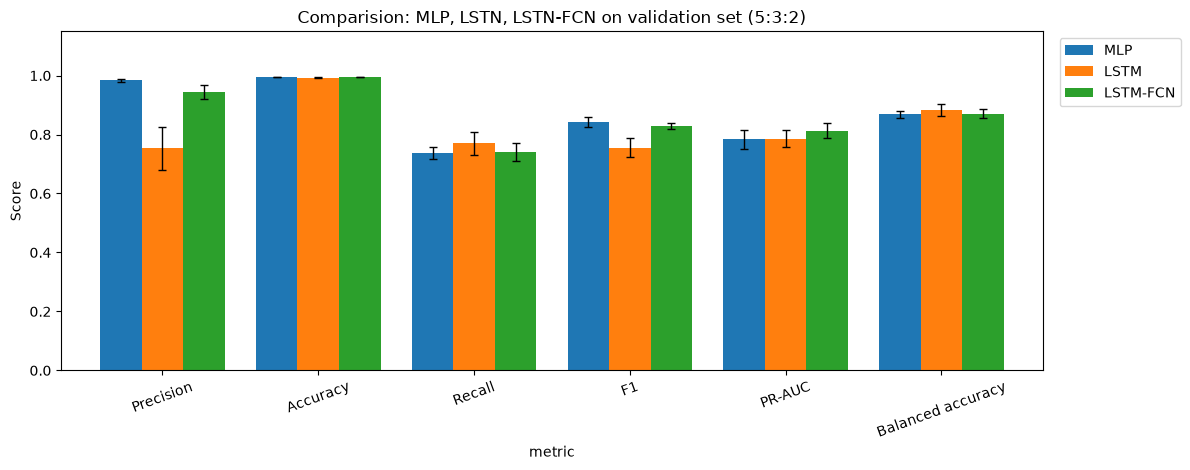

Test set: mean ± SE over 3 seeds


,MLP,LSTM,LSTM-FCN
metric,,,
Precision,0.994 ± 0.004,0.98 ± 0.01,0.82 ± 0.073
Accuracy,0.997 ± 0.0,0.998 ± 0.0,0.995 ± 0.001
Recall,0.745 ± 0.022,0.815 ± 0.044,0.748 ± 0.013
F1,0.851 ± 0.013,0.888 ± 0.023,0.779 ± 0.032
PR-AUC,0.829 ± 0.028,0.913 ± 0.029,0.836 ± 0.005
Balanced accuracy,0.873 ± 0.011,0.907 ± 0.022,0.873 ± 0.006


Individual seeds


MLP                 LSTM               LSTM-FCN         \
seed                 520    42     121    520    42     121      520    42    
metric                                                                        
Precision          0.988  1.000  0.996  0.968  1.000  0.972    0.675  0.904   
Accuracy           0.997  0.997  0.997  0.997  0.997  0.999    0.993  0.996   
Recall             0.784  0.706  0.745  0.790  0.755  0.900    0.765  0.758   
F1                 0.874  0.828  0.852  0.870  0.860  0.935    0.717  0.825   
PR-AUC             0.885  0.798  0.805  0.905  0.868  0.967    0.826  0.843   
Balanced accuracy  0.892  0.853  0.873  0.895  0.877  0.950    0.880  0.879   

                          
seed                 121  
metric                    
Precision          0.882  
Accuracy           0.996  
Recall             0.723  
F1                 0.794  
PR-AUC             0.841  
Balanced accuracy  0.861

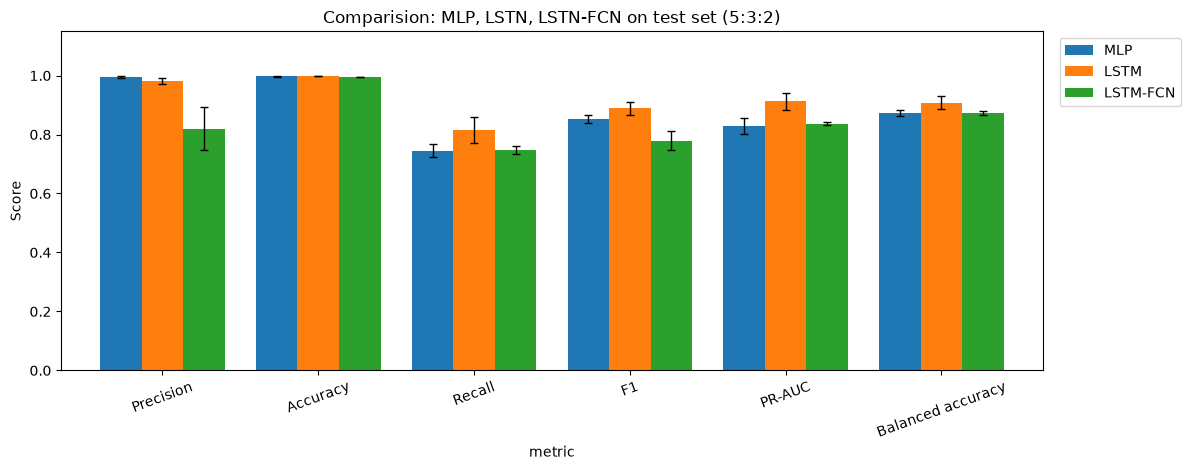

In [441]:
from matplotlib.container import BarContainer

def plot_seed_bars(results, split_name, models=('MLP', 'LSTM', 'LSTM-FCN')):
   
    models = list(models)
    per_seed = pd.concat(results, keys=SEEDS[:len(results)], names=['seed', 'metric'])
    n_runs = len(results)

    grp   = per_seed.groupby(level='metric', sort=False)
    mean_ = grp.mean().reindex(key)[models]
    se_   = (grp.std(ddof=1).reindex(key)[models]) / np.sqrt(n_runs)

    print(f'{split_name.capitalize()} set: mean ± SE over {n_runs} seeds')
    display(mean_.round(3).astype(str) + ' ± ' + se_.round(3).astype(str))
    print('Individual seeds')
    display(per_seed.unstack('seed').reindex(key).round(3))

    ax = mean_.plot.bar(figsize=(12, 4.8), rot=20, width=0.8,yerr=se_, capsize=3, error_kw={'elinewidth': 1})
    ax.set(ylim=(0, 1.15), ylabel='Score',
    title=f'Comparision: MLP, LSTN, LSTN-FCN on {split_name} set (5:3:2)')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.show()
    return mean_, se_

val_mean,  val_se  = plot_seed_bars(seed_results_val, 'validation')
test_mean, test_se = plot_seed_bars(seed_results,     'test')

**HPO/ Optuna**

In [132]:
import optuna
from optuna.visualization.matplotlib import (plot_optimization_history, plot_param_importances, plot_slice)
import os
from sklearn.metrics import (recall_score, precision_score, precision_recall_curve, average_precision_score)



TUNE_EPOCHS   = 15
TUNE_PATIENCE = 5
TUNE_STRIDE   = 2      
MIN_PRECISION = 0.9    
                       
REC_THRESHOLD = 0.5
AP_TIEBREAK   = 1e-4   
optuna.logging.set_verbosity(optuna.logging.INFO)


def recall_for_trial(y, prob):
    """NEW: validation recall + the precision and PR-AUC that go with it."""
    ap = average_precision_score(y, prob)
    if MIN_PRECISION is None:
        pred = (prob >= REC_THRESHOLD).astype(int)     
        rec  = recall_score(y, pred, zero_division=0)
        prec = precision_score(y, pred, zero_division=0)
    else:
        p, r, _ = precision_recall_curve(y, prob)
        i = np.argmax(np.where(p >= MIN_PRECISION, r, -1))   
        rec, prec = float(r[i]), float(p[i])
    return rec, prec, ap


def fit_for_trial(model, train_loader, val_loader, criterion, trial, lr, weight_decay=0.0, val_mask=None):
  
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_score, wait = -np.inf, 0
    for epoch in range(TUNE_EPOCHS):
       
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()

        _, prob, y = run_epoch(model, val_loader, criterion)
        if val_mask is not None:
            prob, y = prob[val_mask], y[val_mask]

        rec, prec, ap = recall_for_trial(y, prob)      
        score = rec + AP_TIEBREAK * ap               

        trial.report(score, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

        if score > best_score:
            best_score, wait = score, 0                
            trial.set_user_attr('best_epoch', epoch + 1)
            trial.set_user_attr('val_recall', rec)     
            trial.set_user_attr('val_precision', prec)
            trial.set_user_attr('val_pr_auc', ap)
        else:
            wait += 1
            if wait >= TUNE_PATIENCE:
                break
    return best_score



In [133]:
MIN_PRECISION = 0.9   
                      
def mlp_objective(trial):
    n_layers = trial.suggest_int('n_layers', 1, 5)
    hidden   = tuple(trial.suggest_int(f'units_{i}', 16, 256, log=True) for i in range(n_layers))
    dropout  = trial.suggest_float('dropout', 0.0, 0.6)
    lr       = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    bs       = trial.suggest_categorical('batch_size', [128, 256, 512])

    set_seed(SEED)
    model = MLP(len(feature_cols), hidden=hidden, dropout=dropout).to(DEVICE)
    train_loader = DataLoader(TensorDataset(X_train_mlp, y_train_mlp), batch_size=bs, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
    criterion = nn.BCEWithLogitsLoss()                   

    return fit_for_trial(model, train_loader, mlp_val_loader, criterion, trial, lr, weight_decay=0.0)


mlp_study = optuna.create_study(
    study_name='mlp_fault_recall_unweighted',   
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
    storage='sqlite:///optuna_mlp.db', load_if_exists=True)

if len(mlp_study.trials) == 0:
    mlp_study.enqueue_trial({'n_layers': 2, 'units_0': 64, 'units_1': 32, 'dropout': 0.2,
                             'lr': 1e-3, 'batch_size': 256})

mlp_study.optimize(mlp_objective, n_trials=40, timeout=60 * 60)
print('Best value:', round(mlp_study.best_value, 4))
print('Best params:', mlp_study.best_params)
print('Val recall / precision / PR-AUC of best trial:',
      {k: round(v, 4) for k, v in mlp_study.best_trial.user_attrs.items() if k.startswith('val_')})

[I 2026-10-15 00:07:40,051] Using an existing study with `study_name='mlp_fault_recall_unweighted'` instead of creating a new one.
[I 2026-10-15 00:07:56,132] Trial 2 finished with value: 0.6020400155934578 and parameters: {'n_layers': 3, 'units_0': 28, 'units_1': 16, 'units_2': 54, 'dropout': 0.393193649861479, 'lr': 0.0004213143049476839, 'batch_size': 256}. Best is trial 2 with value: 0.6020400155934578.
[I 2026-10-15 00:08:15,994] Trial 3 finished with value: 0.6678350454736869 and parameters: {'n_layers': 2, 'units_0': 246, 'units_1': 131, 'dropout': 0.2703994162419994, 'lr': 0.00012876157043517826, 'batch_size': 128}. Best is trial 3 with value: 0.6678350454736869.
[I 2026-10-15 00:08:38,174] Trial 4 finished with value: 0.6579635889269096 and parameters: {'n_layers': 3, 'units_0': 80, 'units_1': 82, 'units_2': 28, 'dropout': 0.2628679243385155, 'lr': 0.00011071011833948371, 'batch_size': 128}. Best is trial 3 with value: 0.6678350454736869.
[I 2026-10-15 00:08:52,412] Trial 5 fi

Best value: 0.9014
Best params: {'n_layers': 5, 'units_0': 134, 'units_1': 123, 'units_2': 155, 'units_3': 94, 'units_4': 18, 'dropout': 0.1101225110069384, 'lr': 0.0016862497559204865, 'batch_size': 512}
Val recall / precision / PR-AUC of best trial: {'val_pr_auc': 0.9306, 'val_precision': 0.9013, 'val_recall': 0.9013}


In [269]:
loss_fn_lstm = nn.BCEWithLogitsLoss()

WINDOW = 40   
STRIDE = 1    

class BatchWindowDataset(Dataset):
    """Sliding windows that never cross from one batch into the next.
    Sample = the last WINDOW time steps, label = fault flag at the window's last step."""
    def __init__(self, data, window=WINDOW, stride=STRIDE):
        self.window = window
        self.X, self.y, self.index, meta = [], [], [], []
        for _, d in data.groupby(batch_col, sort=False):
            k = len(self.X)
            self.X.append(torch.tensor(d[feature_cols].to_numpy(), dtype=torch.float32))
            self.y.append(torch.tensor(d[faulty_col].to_numpy(), dtype=torch.float32))
            ends = list(range(window, len(d) + 1, stride))
            self.index += [(k, e) for e in ends]
      
            meta.append(d.iloc[[e - 1 for e in ends]][[batch_col, time_col, faulty_col]])
        self.meta = pd.concat(meta).reset_index(drop=True)

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        k, e = self.index[i]
        return self.X[k][e - self.window:e], self.y[k][e - 1]

lstm_train_ds = BatchWindowDataset(train_df)
lstm_val_ds   = BatchWindowDataset(val_df)
lstm_test_ds  = BatchWindowDataset(test_df)

g_lstm = torch.Generator().manual_seed(SEED)
lstm_train_loader = DataLoader(lstm_train_ds, batch_size=batch_size, shuffle=True, generator=g_lstm)
lstm_val_loader   = DataLoader(lstm_val_ds,   batch_size=batch_size, shuffle=False)
lstm_test_loader  = DataLoader(lstm_test_ds,  batch_size=batch_size, shuffle=False)

print('LSTM train:')
lstm_criterion = loss_fn_lstm
print('Windows: train', len(lstm_train_ds), '| val', len(lstm_val_ds), '| test', len(lstm_test_ds))
xb, yb = next(iter(lstm_train_loader))
print('One batch:', tuple(xb.shape), tuple(yb.shape))   

LSTM train:
Windows: train 74953 | val 17391 | test 17691
One batch: (256, 40, 23) (256,)


In [270]:
import inspect

WINDOW_CHOICES = [10, 20, 30, 40, 50]
MAX_WINDOW = max(WINDOW_CHOICES)
_lstm_cache = {}    

assert 'healthy' not in inspect.signature(BatchWindowDataset.__init__).parameters, \
    'BatchWindowDataset was overwritten by the LSTM-AE cell - re-run the LSTM dataset cell first'


def lstm_tuning_data(window):
    """Window datasets for one window length, built once and cached."""
    if window not in _lstm_cache:
        tr_ds = BatchWindowDataset(train_df, window=window, stride=TUNE_STRIDE) 
        va_ds = BatchWindowDataset(val_df,   window=window, stride=1)            
       
        mask = np.array([e >= MAX_WINDOW for _, e in va_ds.index])
        _lstm_cache[window] = (tr_ds, va_ds, mask)
    return _lstm_cache[window]


def lstm_objective(trial):
    window  = trial.suggest_categorical('window', WINDOW_CHOICES)
    hidden  = trial.suggest_int('hidden', 16, 128, log=True)
    layers  = trial.suggest_int('num_layers', 1, 5)
    dropout = trial.suggest_float('dropout', 0.0, 0.5)
    lr      = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    bs      = trial.suggest_categorical('batch_size', [32, 64, 128, 256, 512])

    tr_ds, va_ds, mask = lstm_tuning_data(window)
    set_seed(SEED)
    model = LSTMClassifier(len(feature_cols), hidden=hidden, num_layers=layers, dropout=dropout).to(DEVICE)
    train_loader = DataLoader(tr_ds, batch_size=bs, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
    val_loader   = DataLoader(va_ds, batch_size=512, shuffle=False)
    return fit_for_trial(model, train_loader, val_loader, loss_fn_lstm, trial, lr, val_mask=mask)


lstm_study = optuna.create_study(
    study_name='lstm_fault_recall', direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=2),
    storage='sqlite:///optuna_lstm.db', load_if_exists=True)


if len(lstm_study.trials) == 0:
    assert WINDOW in WINDOW_CHOICES and batch_size in [32, 64, 128, 256, 512]
    lstm_study.enqueue_trial({'window': WINDOW, 'hidden': 64, 'num_layers': 2, 'dropout': 0.2,
                              'lr': 1e-3, 'batch_size': batch_size})

lstm_study.optimize(lstm_objective, n_trials=25, timeout=2 * 60 * 60)   # 25 trials or 2 hours

print('Best value:', round(lstm_study.best_value, 4))
print('Best params:', lstm_study.best_params)
print('Val recall / precision / PR-AUC of best trial:',
      {k: round(v, 4) for k, v in lstm_study.best_trial.user_attrs.items() if k.startswith('val_')})

[I 2026-10-15 13:42:48,465] Using an existing study with `study_name='lstm_fault_recall'` instead of creating a new one.
[I 2026-10-15 13:42:50,623] Trial 25 pruned. 
[I 2026-10-15 13:42:53,050] Trial 26 pruned. 
[I 2026-10-15 13:42:55,056] Trial 27 pruned. 
[I 2026-10-15 13:42:57,980] Trial 28 pruned. 
[I 2026-10-15 13:43:00,282] Trial 29 pruned. 
[I 2026-10-15 13:43:07,936] Trial 30 pruned. 
[I 2026-10-15 13:43:17,695] Trial 31 finished with value: 0.8981197194097378 and parameters: {'window': 40, 'hidden': 34, 'num_layers': 2, 'dropout': 0.22256616682068456, 'lr': 0.005857655328935405, 'batch_size': 256}. Best is trial 17 with value: 0.9014083416666729.
[I 2026-10-15 13:43:20,459] Trial 32 pruned. 
[I 2026-10-15 13:43:29,496] Trial 33 finished with value: 0.9046965503433217 and parameters: {'window': 40, 'hidden': 46, 'num_layers': 2, 'dropout': 0.3101104547384426, 'lr': 0.004031120879370218, 'batch_size': 256}. Best is trial 33 with value: 0.9046965503433217.
[I 2026-10-15 13:43:33

Best value: 0.908
Best params: {'window': 40, 'hidden': 40, 'num_layers': 2, 'dropout': 0.1300861509279274, 'lr': 0.00452117751797825, 'batch_size': 256}
Val recall / precision / PR-AUC of best trial: {'val_pr_auc': 0.905, 'val_precision': 0.902, 'val_recall': 0.9079}


In [139]:
FCN_WINDOW      = WINDOW    # the LSTM's window (the tuned one if you ran the LSTM retraining cell)
TUNE_FCN_WINDOW = True     # True = also search the window (see note at the bottom)

# Filter sizes and kernel sets as named options (Optuna can only store simple values, not tuples)
KERNEL_SETS = {'8-5-3': (8, 5, 3), '5-3-3': (5, 3, 3), '11-7-5': (11, 7, 5)}


def build_lstm_fcn(p, window):
    """LSTM-FCN from a parameter dict. window is passed explicitly: the class default
    (window=WINDOW) was fixed when the class was defined, and dim_shuffle needs the real value."""
    f = p['base_filters']
    return LSTMFCN(len(feature_cols), window=window, hidden=p['hidden'],
                   lstm_dropout=p['lstm_dropout'], filters=(f, 2 * f, f),
                   kernels=KERNEL_SETS[p['kernels']], dim_shuffle=p['dim_shuffle'])


def lstm_fcn_objective(trial):
    window = (trial.suggest_categorical('window', WINDOW_CHOICES) if TUNE_FCN_WINDOW
              else FCN_WINDOW)
    p = {
        'hidden':       trial.suggest_int('hidden', 16, 128, log=True),
        'lstm_dropout': trial.suggest_float('lstm_dropout', 0.0, 0.8),   # the LSTM-FCN paper used 0.8
        'base_filters': trial.suggest_categorical('base_filters', [32, 64, 128]),  # filters = (f, 2f, f)
        'kernels':      trial.suggest_categorical('kernels', list(KERNEL_SETS)),
        'dim_shuffle':  trial.suggest_categorical('dim_shuffle', [False, True]),
    }
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    bs = trial.suggest_categorical('batch_size', [64, 128, 256, 512])

    tr_ds, va_ds, mask = lstm_tuning_data(window)          # same cached windows as the LSTM search
    set_seed(SEED)
    model = build_lstm_fcn(p, window).to(DEVICE)
    train_loader = DataLoader(tr_ds, batch_size=bs, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
    val_loader   = DataLoader(va_ds, batch_size=512, shuffle=False)
    return fit_for_trial(model, train_loader, val_loader, loss_fn_lstm, trial, lr, val_mask=mask)


lstm_fcn_study = optuna.create_study(
    study_name='lstm_fcn_fault_recall' + ('_win' if TUNE_FCN_WINDOW else ''),
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=2),
    storage='sqlite:///optuna_lstm_fcn.db', load_if_exists=True)

# Baseline = your current LSTM-FCN (hidden 64, dropout 0.2, filters 128-256-128, kernels 8-5-3)
if len(lstm_fcn_study.trials) == 0:
    baseline = {'hidden': 64, 'lstm_dropout': 0.2, 'base_filters': 128, 'kernels': '8-5-3',
                'dim_shuffle': False, 'lr': 1e-3, 'batch_size': 256}
    if TUNE_FCN_WINDOW:
        baseline['window'] = FCN_WINDOW
    lstm_fcn_study.enqueue_trial(baseline)

lstm_fcn_study.optimize(lstm_fcn_objective, n_trials=25, timeout=2 * 60 * 60)   # 25 trials or 2 hours

print('Best value:', round(lstm_fcn_study.best_value, 4))
print('Best params:', lstm_fcn_study.best_params)
print('Val recall / precision / PR-AUC of best trial:',
      {k: round(v, 4) for k, v in lstm_fcn_study.best_trial.user_attrs.items() if k.startswith('val_')})

[I 2026-10-15 01:20:09,015] A new study created in RDB with name: lstm_fcn_fault_recall_win
[I 2026-10-15 01:20:24,815] Trial 0 finished with value: 0.8060044510488718 and parameters: {'window': 40, 'hidden': 64, 'lstm_dropout': 0.2, 'base_filters': 128, 'kernels': '8-5-3', 'dim_shuffle': False, 'lr': 0.001, 'batch_size': 256}. Best is trial 0 with value: 0.8060044510488718.
[I 2026-10-15 01:20:39,240] Trial 1 finished with value: 0.10860961687729723 and parameters: {'window': 50, 'hidden': 30, 'lstm_dropout': 0.04769008904159096, 'base_filters': 32, 'kernels': '8-5-3', 'dim_shuffle': False, 'lr': 0.00010817877265546797, 'batch_size': 512}. Best is trial 0 with value: 0.8060044510488718.
[I 2026-10-15 01:20:50,765] Trial 2 finished with value: 0.6908697620742196 and parameters: {'window': 40, 'hidden': 24, 'lstm_dropout': 0.21922788233216706, 'base_filters': 64, 'kernels': '8-5-3', 'dim_shuffle': True, 'lr': 0.0010057791188336448, 'batch_size': 256}. Best is trial 0 with value: 0.80600

Best value: 0.8948
Best params: {'window': 40, 'hidden': 60, 'lstm_dropout': 0.640627402427069, 'base_filters': 128, 'kernels': '11-7-5', 'dim_shuffle': False, 'lr': 0.0032500398442507346, 'batch_size': 64}
Val recall / precision / PR-AUC of best trial: {'val_pr_auc': 0.9185, 'val_precision': 0.9007, 'val_recall': 0.8947}


**EXP2: Window**

**Weighted vs unweighted BCE**

faulty: 642 | healthy: 74311 | pos_weight: 11.5749

=== LSTM | BCE ===
epoch   1 | train loss 0.0505 | val loss 0.0417 | AP 0.6672 | val precision 0.9242 | val accuracy 0.9890 | val recall 0.4013 | val f1 0.5596
epoch   5 | train loss 0.0021 | val loss 0.0181 | AP 0.9116 | val precision 0.9777 | val accuracy 0.9973 | val recall 0.8651 | val f1 0.9180
epoch  10 | train loss 0.0006 | val loss 0.0245 | AP 0.9019 | val precision 0.9923 | val accuracy 0.9972 | val recall 0.8487 | val f1 0.9149
Early stopping at epoch 12.
Restored best model from epoch 7 (val recall 0.875, val AP 0.910), f1 score 0.870

=== LSTM-FCN | BCE ===
epoch   1 | train loss 0.0162 | val loss 0.0380 | AP 0.7894 | val precision 0.9320 | val accuracy 0.9928 | val recall 0.6316 | val f1 0.7529
epoch   5 | train loss 0.0016 | val loss 0.0503 | AP 0.7809 | val precision 0.9854 | val accuracy 0.9940 | val recall 0.6645 | val f1 0.7937
epoch  10 | train loss 0.0011 | val loss 0.0624 | AP 0.8377 | val precision 0.9949 | val a

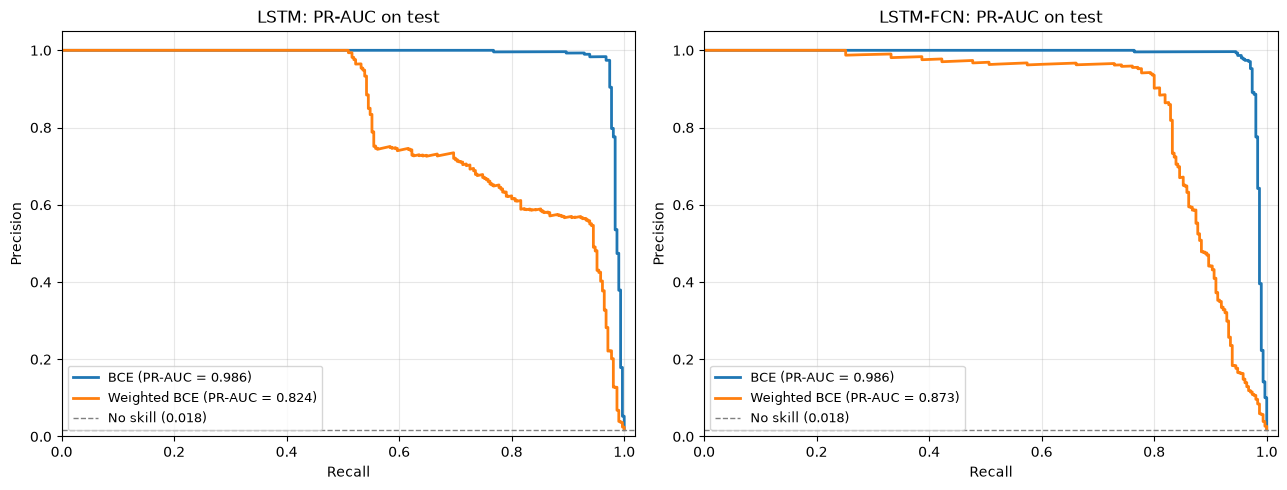

In [271]:
def train_and_get_probs(make_model, criterion, batch_size, lr, epochs, patience):

    set_seed(SEED)
    model = make_model().to(DEVICE)
    train_loader = DataLoader(lstm_train_ds, batch_size=batch_size, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
    fit(model, train_loader, lstm_val_loader, criterion, epochs=epochs, lr=lr, patience=patience)
    _, test_prob, test_true = run_epoch(model, lstm_test_loader, criterion)
    return test_true, test_prob


train_labels = torch.tensor(lstm_train_ds.meta[faulty_col].to_numpy(), dtype=torch.float32)
LOSSES = {
    'BCE':          nn.BCEWithLogitsLoss(),
    'Weighted BCE': weightedBCE(train_labels),
}

lstm_curves, fcn_curves = {}, {}
for name, criterion in LOSSES.items():
    print(f'\n=== LSTM | {name} ===')
    lstm_curves[name] = train_and_get_probs(
        lambda: LSTMClassifier(n_in=len(feature_cols)), criterion,
        batch_size=batch_size, lr=0.0026, epochs=50, patience=5)

    print(f'\n=== LSTM-FCN | {name} ===')
    fcn_curves[name] = train_and_get_probs(
        lambda: build_lstm_fcn(best_fcn, WINDOW), criterion,
        batch_size=best_fcn['batch_size'], lr=best_fcn['lr'], epochs=15, patience=8)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_pr_curves(lstm_curves, 'LSTM: PR-AUC on test', ax=axes[0])
plot_pr_curves(fcn_curves,  'LSTM-FCN: PR-AUC on test', ax=axes[1])
plt.tight_layout();
plt.show()

**Online Sensor**

In [ ]:
print(feature_cols)

['Aeration rate(Fg:L/h)', 'Sugar feed rate(Fs:L/h)', 'Acid flow rate(Fa:L/h)', 'Base flow rate(Fb:L/h)', 'Heating/cooling water flow rate(Fc:L/h)', 'Heating water flow rate(Fh:L/h)', 'Water for injection/dilution(Fw:L/h)', 'Air head pressure(pressure:bar)', 'Dumped broth flow(Fremoved:L/h)', 'Substrate concentration(S:g/L)', 'Dissolved oxygen concentration(DO2:mg/L)', 'Penicillin concentration(P:g/L)', 'Vessel Volume(V:L)', 'Vessel Weight(Wt:Kg)', 'pH(pH:pH)', 'Temperature(T:K)', 'Generated heat(Q:kJ)', 'carbon dioxide percent in off-gas(CO2outgas:%)', 'PAA flow(Fpaa:PAA flow (L/h))', 'Oil flow(Foil:L/hr)', 'Oxygen Uptake Rate(OUR:(g min^{-1}))', 'Oxygen in percent in off-gas(O2:O2  (%))', 'Carbon evolution rate(CER:g/h)']


In [312]:
process_groups = {
    'Manipulated' : ['Fg', 'Fs', 'Fa', 'Fb', 'Fc', 'Fh', 'Fw', 'pressure', 'Fremoved', 'Fpaa', 'Foil'],
    'Sensors' : ['DO2', 'V', 'Wt', 'pH', 'T'],
    'Off-gas' : ['CO2outgas', 'O2', 'OUR', 'CER'],
    'States' : ['S', 'P', 'Q'],
}

symbol = {c: c.split('(', 1)[1].split(':', 1)[0].strip() for c in feature_cols}
GROUPS = {g: [c for c in feature_cols if symbol[c] in syms] for g, syms in process_groups.items()}
group_of = {c: g for g, cols in GROUPS.items() for c in cols}

missing = [c for c in feature_cols if c not in group_of]
display(pd.DataFrame([(g, len(cols), ', '.join(symbol[c] for c in cols)) for g, cols in GROUPS.items()],
                     columns=['Group', 'n', 'Variables']))


,Group,n,Variables
0,Manipulated,11,"Fg, Fs, Fa, Fb, Fc, Fh, Fw, pressure, Fremoved..."
1,Sensors,5,"DO2, V, Wt, pH, T"
2,Off-gas,4,"CO2outgas, OUR, O2, CER"
3,States,3,"S, P, Q"


**NEw try**

In [ ]:
FS_SEEDS = [520, 42, 121]
fs_loss  = nn.BCEWithLogitsLoss()
FS_LSTM  = dict(hidden=45, num_layers=1, dropout=0.33, lr=0.0026, batch_size=256)

BASELINE = 'All features'
FEATURE_SETS = {BASELINE: list(feature_cols)}

for group in GROUPS:                               
    FEATURE_SETS[f'Without {group}'] = [c for c in feature_cols if group_of[c] != group]

for group, cols in GROUPS.items():                
    FEATURE_SETS[f'Only {group}'] = list(cols)

display(pd.DataFrame({'n inputs': {name: len(cols) for name, cols in FEATURE_SETS.items()}}))

class FeatureWindowDataset(Dataset):

    def __init__(self, data, cols, window=WINDOW, stride=1):
        self.window = window
        self.X, self.y = [], []     
        self.index = []            
        last_steps = []             

        for _, batch in data.groupby(batch_col, sort=False):
            k = len(self.X)
            self.X.append(torch.tensor(batch[cols].to_numpy(), dtype=torch.float32))
            self.y.append(torch.tensor(batch[faulty_col].to_numpy(), dtype=torch.float32))

            ends = range(window, len(batch) + 1, stride)
            self.index += [(k, end) for end in ends]
            last_steps.append(batch.iloc[[end - 1 for end in ends]][[batch_col, time_col, faulty_col]])

        self.meta = pd.concat(last_steps).reset_index(drop=True)

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        k, end = self.index[i]
        return self.X[k][end - self.window:end], self.y[k][end - 1]

,n inputs
All features,23
Without Manipulated,12
Without Sensors,18
Without Off-gas,19
Without States,20
Only Manipulated,11
Only Sensors,5
Only Off-gas,4
Only States,3


In [ ]:
fs_rows = []  

def train_lstm(fs_name, cols, train_ds, val_loader, seed):
    set_seed(seed)
    model = LSTMClassifier(n_in=len(cols), hidden=FS_LSTM['hidden'],
                           num_layers=FS_LSTM['num_layers'], dropout=FS_LSTM['dropout']).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'\n=== {fs_name} | {len(cols)} inputs, {n_params:,} params | seed {seed} ===')

    train_loader = DataLoader(train_ds, batch_size=FS_LSTM['batch_size'], shuffle=True,
                              generator=torch.Generator().manual_seed(seed))
    best_epoch, val_ap = fit_pr_auc(model, train_loader, val_loader, fs_loss, lr=FS_LSTM['lr'])
    return model, n_params, best_epoch, val_ap

def test_pr_auc(model, test_loader):
    _, prob, y = run_epoch(model, test_loader, fs_loss)
    return average_precision_score(y.astype(int), prob)

for fs_name, cols in FEATURE_SETS.items():
    # Window datasets for this feature set (built once, shared by all seeds)
    train_ds = FeatureWindowDataset(train_df, cols)
    val_ds   = FeatureWindowDataset(val_df,   cols)
    test_ds  = FeatureWindowDataset(test_df,  cols)
    val_loader  = DataLoader(val_ds,  batch_size=512, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=512, shuffle=False)

    for seed in FS_SEEDS:
        start = time.time()
        model, n_params, best_epoch, val_ap = train_lstm(fs_name, cols, train_ds, val_loader, seed)
        test_ap = test_pr_auc(model, test_loader)
        minutes = (time.time() - start) / 60

        fs_rows.append({'feature_set': fs_name, 'n_inputs': len(cols), 'params': n_params, 'seed': seed,
                        'best_epoch': best_epoch, 'minutes': minutes,
                        'val_pr_auc': val_ap, 'test_pr_auc': test_ap})
        print(f'val PR-AUC {val_ap:.3f} | test PR-AUC {test_ap:.3f} | {minutes:.1f} min')

fs_res = pd.DataFrame(fs_rows)


=== All features | 23 inputs, 12,646 params | seed 520 ===
epoch   1 | train loss 0.0505 | val PR-AUC 0.6672
epoch   5 | train loss 0.0021 | val PR-AUC 0.9116
epoch  10 | train loss 0.0006 | val PR-AUC 0.9019
Early stopping at epoch 11.
Restored epoch 6 (val PR-AUC 0.9144)
val PR-AUC 0.914 | test PR-AUC 0.986 | 0.2 min

=== All features | 23 inputs, 12,646 params | seed 42 ===
epoch   1 | train loss 0.0574 | val PR-AUC 0.6009
epoch   5 | train loss 0.0026 | val PR-AUC 0.8229
epoch  10 | train loss 0.0009 | val PR-AUC 0.8788
Early stopping at epoch 14.
Restored epoch 9 (val PR-AUC 0.9039)
val PR-AUC 0.904 | test PR-AUC 0.960 | 0.3 min

=== All features | 23 inputs, 12,646 params | seed 121 ===
epoch   1 | train loss 0.0535 | val PR-AUC 0.7164
epoch   5 | train loss 0.0021 | val PR-AUC 0.8867
Early stopping at epoch 8.
Restored epoch 3 (val PR-AUC 0.8979)
val PR-AUC 0.898 | test PR-AUC 0.966 | 0.2 min

=== Without Manipulated | 12 inputs, 10,666 params | seed 520 ===
epoch   1 | train l

Sensor-group experiment, LSTM, test set, mean ± SE over 3 seed(s)


,inputs,parameters,val PR-AUC,test PR-AUC,change vs all features
feature_set,,,,,
All features,23,12646,0.905 ± 0.005,0.971 ± 0.008,+0.000 ± 0.000
Without Manipulated,12,10666,0.539 ± 0.031,0.611 ± 0.011,-0.360 ± 0.004
Without Sensors,18,11746,0.932 ± 0.026,0.605 ± 0.019,-0.366 ± 0.025
Without Off-gas,19,11926,0.919 ± 0.003,0.987 ± 0.004,+0.016 ± 0.010
Without States,20,12106,0.906 ± 0.011,0.992 ± 0.004,+0.021 ± 0.006
Only Manipulated,11,10486,0.846 ± 0.033,0.809 ± 0.032,-0.162 ± 0.030
Only Sensors,5,9406,0.277 ± 0.026,0.558 ± 0.042,-0.412 ± 0.035
Only Off-gas,4,9226,0.517 ± 0.027,0.296 ± 0.020,-0.675 ± 0.013
Only States,3,9046,0.246 ± 0.032,0.012 ± 0.001,-0.959 ± 0.008


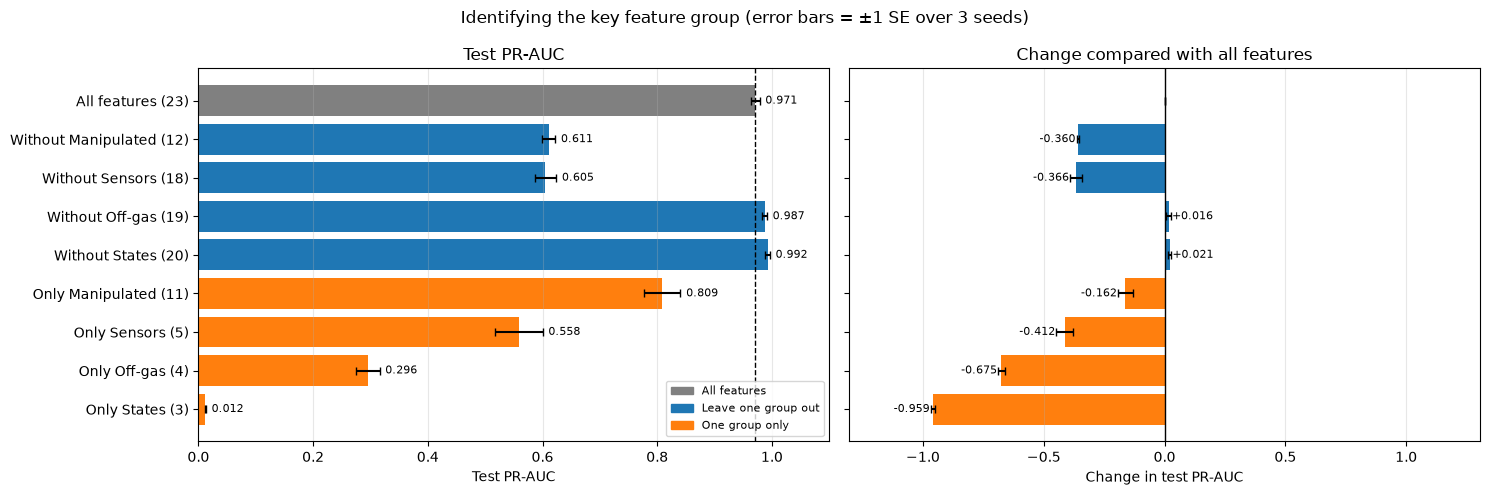

In [ ]:
order = list(FEATURE_SETS)
n = fs_res['seed'].nunique()
base = fs_res[fs_res.feature_set == BASELINE].set_index('seed')['test_pr_auc']
fs_res['delta_pr_auc'] = fs_res['test_pr_auc'] - fs_res['seed'].map(base)

grouped = fs_res.groupby('feature_set')
mean_ = grouped[['n_inputs', 'params', 'val_pr_auc', 'test_pr_auc', 'delta_pr_auc']].mean().reindex(order)
se_   = (grouped[['val_pr_auc', 'test_pr_auc', 'delta_pr_auc']].std(ddof=1) / np.sqrt(n)).reindex(order).fillna(0)


def mean_pm_se(col, sign=False):
    fmt = '{:+.3f}' if sign else '{:.3f}'
    text = mean_[col].map(fmt.format)
    return text + ' ± ' + se_[col].map('{:.3f}'.format) if n > 1 else text


table = pd.DataFrame({
    'inputs':                 mean_['n_inputs'].astype(int),
    'parameters':             mean_['params'].astype(int),
    'val PR-AUC':             mean_pm_se('val_pr_auc'),
    'test PR-AUC':            mean_pm_se('test_pr_auc'),
    'change vs all features': mean_pm_se('delta_pr_auc', sign=True),
})
print(f'Sensor-group experiment, LSTM, test set, mean ± SE over {n} seed(s)')
display(table)


# ---- Figure: test PR-AUC and change vs all features ----
def kind(name):
    if name == BASELINE:
        return 'All features'
    return 'Leave one group out' if name.startswith('Without') else 'One group only'

KIND_COLOR = {'All features': 'grey', 'Leave one group out': 'tab:blue', 'One group only': 'tab:orange'}
colors = [KIND_COLOR[kind(name)] for name in order]
labels = [f'{name} ({int(mean_.loc[name, "n_inputs"])})' for name in order]   # name (number of inputs)
y = np.arange(len(order))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Left: test PR-AUC
ax = axes[0]
ax.barh(y, mean_['test_pr_auc'], xerr=se_['test_pr_auc'], color=colors, capsize=3)
ax.axvline(mean_.loc[BASELINE, 'test_pr_auc'], color='k', ls='--', lw=1)
for i, (v, e) in enumerate(zip(mean_['test_pr_auc'], se_['test_pr_auc'])):
    ax.text(v + e + 0.01, i, f'{v:.3f}', va='center', fontsize=8)
ax.set(xlim=(0, 1.1), xlabel='Test PR-AUC', title='Test PR-AUC')

ax = axes[1]
ax.barh(y, mean_['delta_pr_auc'], xerr=se_['delta_pr_auc'], color=colors, capsize=3)
ax.axvline(0, color='k', lw=1)
for i, (v, e) in enumerate(zip(mean_['delta_pr_auc'], se_['delta_pr_auc'])):
    if order[i] != BASELINE:
        ax.text(v + e + 0.005 if v >= 0 else v - e - 0.005, i, f'{v:+.3f}', va='center',
                ha='left' if v >= 0 else 'right', fontsize=8)
lim = (mean_['delta_pr_auc'].abs() + se_['delta_pr_auc']).max() * 1.35
ax.set(xlim=(-lim, lim), xlabel='Change in test PR-AUC', title='Change compared with all features')

for ax in axes:
    ax.grid(axis='x', alpha=0.3)
axes[0].set_yticks(y, labels)
axes[0].invert_yaxis()
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in KIND_COLOR.values()],
               labels=list(KIND_COLOR), loc='lower right', fontsize=8)

err = f'error bars = ±1 SE over {n} seeds' if n > 1 else '1 seed'
fig.suptitle(f'Identifying the key feature group ({err})')
plt.tight_layout()
plt.show()